# GLOFWatch · Combined DeepLab inference, monitoring, and JEV dataset collection

Run in order: configuration → imports and function definitions → authentication and registry → bounded live backfill → live collection/export. For a larger dataset, enable the historical collection section and rerun its bounded cell until it finishes. Then review the label templates and run the training export section. All saved notebook outputs have been cleared; run them to obtain your own measurements.

## 1. Configuration — edit this cell

`REGISTRY_MODE="seeds"` uses the 14 supplied lakes. `"csv"` uses your reviewed registry. `"discover"` runs the existing candidate detector and caches a separate registry, capped at `MAX_LAKES` total. Inspect candidate lake footprints before treating their area changes as lake measurements. Historical work should use a fixed reviewed registry with lake identities and footprints suitable for the historical period.

In [1]:
import gc
gc.collect()

23

In [2]:
from pathlib import Path

PROJECT_DIR = Path(".").resolve()
MODEL_FILENAME = "final_model.keras"          # change this one filename for your model
MODEL_PATH = PROJECT_DIR / "models" / "deeplab" / MODEL_FILENAME
WORK_DIR = PROJECT_DIR
GEE_PROJECT = "glof-510607"
DB_FILENAME = "glof_monitor.sqlite"  # choose the database to continue
ADOPT_UNVERSIONED_DB = True
FEATURES_FILENAME = "features"                # retains your existing inference handoff filename
SNAPSHOT_FILENAME = "latest_path"             # retains your existing dashboard snapshot filename

REGISTRY_MODE = "discover"                       # seeds | csv | discover
REGISTRY_CSV = PROJECT_DIR / "lake_registry.csv"
MAX_LAKES = 80                               # total cap, including seeds
DISCOVERY_REGIONS = ["Uttarakhand", "Sikkim_East_Nepal", "Ladakh_Zanskar"]
# DISCOVERY_REGIONS =  ["Karakoram_HinduKush" ,"Ladakh_Zanskar", "Himachal_Spiti", "Uttarakhand",
#                    "West_Nepal", "Central_Nepal", "Sikkim_East_Nepal", "Bhutan", "Arunachal" ]  
DISCOVERY_SEASON_YEAR = 2022                  # fixed season; review relevance to your study period
ACTIVE_LAKE_IDS = ()                         # empty tuple means all selected lakes

SEGMENTATION_THRESHOLD_CONFIG = 0.5          # validation-selected threshold; metadata overrides if present
LIVE_BACKFILL_DAYS = 120
DOWNLOAD_BUDGET_CONFIG = 24                  # CPU start; try 48 or 96 after measuring throughput
MAX_BACKFILL_PASSES = 6                      # bounded; rerun until backlog is zero
POLL_HOURS = 6                               # spacing for later live collection times
RUN_LOCAL_IMAGE_TEST = False
RUN_LAKE_SMOKE_TEST = True
RUN_EVENT_IMAGES = True

# Historical dataset settings. Endpoints are inclusive; use past dates.
RUN_HISTORICAL_COLLECTION = True
HIST_START = "2023-06-01T00:00:00Z"
HIST_END = "2023-10-10T00:00:00Z"
HIST_STEP_HOURS = 24                         # daily general sampling; 6 around event windows
HIST_WARMUP_DAYS = 120                       # extra observations before HIST_START
MAX_HISTORICAL_CLOCKS_PER_RUN = 4             # bounded, resumable; increase after a pilot run
S2_AVAILABILITY_LAG_HOURS = 48                # assumption, not verified provider ingest timestamps
S1_AVAILABILITY_LAG_HOURS = 48
HIST_CONTEXT_CSV = None                      # optional archive; format described below
HIST_WORK_DIR = WORK_DIR / "historical"       # use a new folder when changing the feature profile
ALLOW_ASSUMED_SATELLITE_LAGS_FOR_TRAINING = False

RUN_LABEL_EXPORT = False                    # enable after reviewing event/control templates
EVENT_LABELS_CSV = WORK_DIR / "jev_events_REVIEW.csv"
CONTROL_LABELS_CSV = WORK_DIR / "jev_controls_REVIEW.csv"
ALLOW_SYNTHETIC_DEMO = False

## 2. Dependencies and your DeepLab model

Use the TensorFlow/Keras version compatible with the model you trained. Run the installation cell if these packages are missing; TensorFlow itself should already be installed in your training/inference environment. Restart the kernel only if your package installer requires it, then run from the top.

In [3]:
%pip install -q earthengine-api rasterio shapely pyproj requests opencv-python-headless scipy pandas numpy matplotlib pillow scikit-learn albumentations scikit-image

Note: you may need to restart the kernel to use updated packages.


In [4]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.layers import (Layer, Conv2D, BatchNormalization, ReLU,
    AveragePooling2D, UpSampling2D, Concatenate, Dropout, Activation)
from tensorflow.keras.applications import ResNet50
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

2026-10-11 05:02:58.592353: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
import warnings
warnings.filterwarnings("ignore")

import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.layers import (Layer, Conv2D, BatchNormalization, ReLU, AveragePooling2D,
                                     UpSampling2D, Concatenate, Dropout, Activation)
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

import albumentations as A
from sklearn.model_selection import GroupShuffleSplit
from skimage.filters import threshold_otsu

In [6]:
import os, io, json, math, time, sqlite3, hashlib, zipfile
from types import SimpleNamespace
from datetime import datetime, timezone
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import requests
import cv2
import matplotlib.pyplot as plt
from rasterio.io import MemoryFile
from rasterio.features import rasterize
from shapely.geometry import shape, mapping, Point
from shapely.ops import transform as shp_transform, unary_union
from pyproj import CRS, Transformer
from scipy.spatial import cKDTree
import ee

In [7]:
### Params
# ------------------------------------------------------------------ stage 0: lake registry
ELEV_MIN_M        = 3000      # glacial lakes in the Himalaya are rarely lower
SLOPE_MAX_DEG     = 12        # lakes are flat: removes most terrain-shadow false positives
NDWI_T            = 0.10      # (B3-B8)/(B3+B8), candidate generator only; DeepLab does the real measurement
GLACIER_BUFFER_M  = 10_000    # candidate must lie within this distance of a GLIMS glacier
LAKE_MIN_KM2, LAKE_MAX_KM2 = 0.005, 10.0
TILE_DEG          = 0.5       # registry is built tile by tile (keeps each Earth Engine call small)
CLUSTER_KM        = 1.5       # candidates closer than this share one 4 km monitoring chip
SEED_RADIUS_M     = 1000      # footprint radius for seed lakes that have no polygon

# ------------------------------------------------------------------ stage 1: optical ingest
CHIP_M, PIXEL_M, MODEL_SIZE = 4000, 10, 400      # 4 km @ 10 m = 400 x 400 = your training size
FOOTPRINT_BUFFER_M   = 300    # lake area is counted inside (registry footprint + this buffer)
MAX_SCENE_CLOUD_PCT  = 85     # loose scene-level prefilter; the real test is clear pixels *at the lake*
MIN_FOOTPRINT_VALID  = 0.80   # observation is "reliable" only if >=80% of the footprint is cloud-free
BAD_SCL              = (0, 1, 3, 8, 9, 10)       # no-data, saturated, shadow, cloud med/high, cirrus
MODEL_BANDS          = ["B8", "B4", "B3"]        # order your model was trained with
INPUT_MODE           = "reflectance255"          # identical to Inference_try. Alt: "percentile"
SEGMENTATION_THRESHOLD       = 0.50                      # kept name from old notebook; applies to DeepLab output
BACKFILL_DAYS        = 90     # history gathered the first time a lake is seen (builds the baseline)
LOOKBACK_DAYS        = 20     # normal cycles re-check this window (retries failed downloads)
DOWNLOAD_BUDGET      = 24    # max chips per cycle; backlog is cleared over later cycles
EE_WORKERS, DL_WORKERS, CHUNK = 2, 2, 4
SAVE_QUICKLOOKS      = True   # PNG overlays for scenes from the last 15 days

# ------------------------------------------------------------------ stage 2: context
SAR_WINDOW_DAYS = 120      # ~10 same-orbit repeats at a 12-day cycle
SAR_WATER_DB    = -18.0       # VV threshold (dB) for open water. Heuristic, not calibrated.
SAR_MIN_COVER   = 0.90
SAR_MIN_BASELINE_IMAGES = 3   # same-orbit images needed before a SAR change is judged
SAR_MIN_REL_SIGMA = 0.10      # noise floor: at least 10% of baseline, however calm the history looks
SEISMIC_LOOKBACK_DAYS, SEISMIC_MIN_MAG = 7, 2.5
WX_BATCH = 20
ENABLE_GPM = False  # Final IMERG is not a low-latency forecasting input
# ------------------------------------------------------------------ stage 3: detection

In [8]:
from types import SimpleNamespace

D = SimpleNamespace(
    BASELINE_DAYS=120, MIN_HISTORY=3, MIN_LAKE_KM2=0.01,
    DRAWDOWN_PCT=30, SEVERE_DRAWDOWN_PCT=60,       # vs median baseline
    RAPID_PCT=20, RAPID_DAYS=15, MIN_Z=3.0,        # vs previous reliable scene
    SAR_DROP_PCT=40, SAR_RISE_PCT=40, SAR_MIN_Z=3.0,   # SAR needs BOTH a % change and a z-score vs its own noise
    RAIN_24H_MM=50, RAIN_72H_MM=100,
    QUAKE_MAG=4.5, QUAKE_KM=150, QUAKE_HOURS=72,
    RECENT_OPTICAL_DAYS=15, COOLDOWN_HOURS=48,
)
LEVELS = ["GREEN", "YELLOW", "ORANGE", "RED"]
NOTIFY_MIN_LEVEL = "ORANGE"
LEVEL_RANK = {level: i for i, level in enumerate(LEVELS)}

In [9]:
def configure_gpu():
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(device, True)
    return tf.config.list_physical_devices("GPU")

In [10]:
reg = tf.keras.utils.register_keras_serializable(package='glof')

@reg
class ResNetPreprocess(Layer):
    """Keras ResNet50 ImageNet weights expect BGR, mean-subtracted, 0-255 input."""
    def call(self, x):
        x = tf.reverse(x, axis=[-1])
        return x - tf.constant([103.939, 116.779, 123.68], dtype=x.dtype)

@reg
class ConvBlock(Layer):
    def __init__(self, filters=256, kernel_size=3, dilation_rate=1, **kwargs):
        super().__init__(**kwargs)
        self.filters, self.kernel_size, self.dilation_rate = filters, kernel_size, dilation_rate
        self.net = Sequential([
            Conv2D(filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate,
                   use_bias=False, kernel_initializer='he_normal'),
            BatchNormalization(),
            ReLU(),
        ])

    def call(self, X):
        return self.net(X)

    def get_config(self):
        return {**super().get_config(), 'filters': self.filters,
                'kernel_size': self.kernel_size, 'dilation_rate': self.dilation_rate}

In [11]:
print("GPUs:",configure_gpu())

GPUs: []


In [12]:
DATA_DIR = PROJECT_DIR
IMG_DIR = DATA_DIR / "data" / "images"
MODEL_DIR = MODEL_PATH.parent.parent

In [13]:
def load_segmentation(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Place your trained .keras model at {path}")
    loaded = tf.keras.models.load_model(path, compile=False)
    if tuple(loaded.input_shape[1:]) != (400, 400, 3) or tuple(loaded.output_shape[1:]) != (400, 400, 1):
        raise ValueError("Expected a 400x400, three-input-band, one-output DeepLab model")
    return loaded

In [14]:
model = load_segmentation(MODEL_PATH)
print("Model:", model.input_shape, "→", model.output_shape)

Model: (None, 400, 400, 3) → (None, 400, 400, 1)


In [15]:
if RUN_LOCAL_IMAGE_TEST:
    from PIL import Image
    
    ### Local Image Test
    LOCAL_PNG = f"{IMG_DIR}/image_222.png"
    image = np.array(Image.open(LOCAL_PNG).convert("RGB"),dtype=np.float32)
    ### Test Input Image Shape
    if image.shape!=(400,400,3): raise ValueError("Provide a 400x400 training-compatible tile")
    ### Get Model Probabilities
    probabilities = model(image[None],training=False).numpy()[0,...,0]
    # sidecar = cfg.deeplab_path.with_suffix(".metadata.json")
    threshold = 0.5
    fig,axes = plt.subplots(1,3,figsize=(12,4))
    axes[0].imshow(image.astype("uint8"));axes[0].set_title("Input")
    axes[1].imshow(probabilities,vmin=0,vmax=1);axes[1].set_title("Water probability")
    axes[2].imshow(probabilities>=threshold,cmap="gray");axes[2].set_title("Water mask")
    plt.show()
else:
    print("Optional local-image test skipped")

Optional local-image test skipped


## 3. Satellite, database, and assessment functions

In [16]:
def utm_epsg(lon, lat):
    zone = int((lon + 180) / 6) + 1
    return (32600 if lat >= 0 else 32700) + zone

def local_transformers(lat, lon):
    local = CRS.from_proj4(f"+proj=aeqd +lat_0={lat} +lon_0={lon} +datum=WGS84 +units=m")
    return (Transformer.from_crs("EPSG:4326", local, always_xy=True),
            Transformer.from_crs(local, "EPSG:4326", always_xy=True))

def disc_wgs84(lat, lon, radius_m):
    _, to_wgs = local_transformers(lat, lon)
    return shp_transform(to_wgs.transform, Point(0, 0).buffer(radius_m))

In [17]:
def footprint_wgs84(row):
    """Lake footprint polygon (EPSG:4326). Auto-detected lakes carry a polygon; seeds get a disc."""
    gj = row.get("footprint_geojson")
    if isinstance(gj, str) and gj.strip():
        return shape(json.loads(gj))
    return disc_wgs84(row["lat"], row["lon"], SEED_RADIUS_M)

def footprint_ee(row):
    """Footprint (+buffer) as an Earth Engine geometry, for the SAR check."""
    g = footprint_wgs84(row).simplify(1e-4)
    return ee.Geometry(mapping(g)).buffer(FOOTPRINT_BUFFER_M)

def chip_region(lat, lon, size_m=CHIP_M):
    epsg = utm_epsg(lon, lat)
    x, y = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True).transform(lon, lat)
    x, y = round(x / PIXEL_M) * PIXEL_M, round(y / PIXEL_M) * PIXEL_M
    h = size_m / 2
    region = ee.Geometry.Rectangle([x - h, y - h, x + h, y + h], proj=f"EPSG:{epsg}", geodesic=False)
    return region, epsg

def footprint_mask(row, transform, crs, out_shape):
    """Rasterise the buffered footprint onto the chip grid."""
    to_chip = Transformer.from_crs("EPSG:4326", CRS.from_wkt(crs.to_wkt()), always_xy=True)
    g = shp_transform(to_chip.transform, footprint_wgs84(row)).buffer(FOOTPRINT_BUFFER_M)
    return rasterize([(mapping(g), 1)], out_shape=out_shape, transform=transform,
                     fill=0, dtype="uint8").astype(bool)

def haversine_km_vec(lat1, lon1, lat2, lon2):
    r = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

In [18]:
def to_jsonable(o):
    if isinstance(o, dict):                    return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):           return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)):    return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):           return int(o)
    if isinstance(o, (np.bool_,)):             return bool(o)
    if isinstance(o, (pd.Timestamp, datetime)):return o.isoformat()
    return o

def utc(dt):
    t = pd.Timestamp(dt)
    return t.tz_localize("UTC") if t.tzinfo is None else t.tz_convert("UTC")

def configure_gpu():
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(device, True)
    return tf.config.list_physical_devices("GPU")

def iso(dt): return utc(dt).isoformat()

def ee_fmt(dt): return pd.Timestamp(dt).strftime("%Y-%m-%dT%H:%M:%S")

def s2_mask(img):
    scl = img.select("SCL")
    ok = scl.neq(1).And(scl.neq(3)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(ok)

In [19]:
def detect_candidates(tile_bbox, season_year):
    geom = ee.Geometry.Rectangle(list(tile_bbox), proj="EPSG:4326", geodesic=False)
    ndwi = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
            .filterBounds(geom)
            .filterDate(f"{season_year}-08-01", f"{season_year}-12-01")
            .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60))
            .map(s2_mask)
            .map(lambda im: im.normalizedDifference(["B3", "B8"]).rename("ndwi"))
            .median())
    dem_col = ee.ImageCollection("COPERNICUS/DEM/GLO30").select("DEM")
    dem = dem_col.mosaic().setDefaultProjection(dem_col.first().projection())
    slope = ee.Terrain.slope(dem)
    glims = ee.FeatureCollection("GLIMS/current").filterBounds(geom.buffer(GLACIER_BUFFER_M))
    near_glacier = glims.distance(GLACIER_BUFFER_M, 100).lte(GLACIER_BUFFER_M)
    cand = (ndwi.gt(NDWI_T).And(dem.gt(ELEV_MIN_M)).And(slope.lt(SLOPE_MAX_DEG))
            .And(near_glacier).selfMask())
    cand = cand.updateMask(cand.connectedPixelCount(100, True).gte(8))
    vec = cand.reduceToVectors(geometry=geom, scale=20, geometryType="polygon",
                               eightConnected=True, maxPixels=1e10, tileScale=4)
    def add(f):
        g = f.geometry()
        c = g.centroid(10).coordinates()
        return f.set({"area_km2": g.area(10).divide(1e6), "lon": c.get(0), "lat": c.get(1)})
    vec = (vec.map(add).filter(ee.Filter.And(ee.Filter.gte("area_km2", LAKE_MIN_KM2),
                                             ee.Filter.lte("area_km2", LAKE_MAX_KM2))))
    out = []
    for f in vec.getInfo()["features"]:
        p = f["properties"]
        out.append({"lat": float(p["lat"]), "lon": float(p["lon"]),
                    "area_km2": float(p["area_km2"]), "geometry": f["geometry"]})
    return out

In [20]:
def cluster_candidates(cands, radius_km=CLUSTER_KM):
    if not cands:
        return []
    lat0 = float(np.mean([c["lat"] for c in cands]))
    xy = np.array([[c["lon"] * 111.32 * math.cos(math.radians(lat0)), c["lat"] * 110.57] for c in cands])
    tree = cKDTree(xy)
    taken = np.zeros(len(cands), dtype=bool)
    out = []
    for i in np.argsort([-c["area_km2"] for c in cands]):
        if taken[i]:
            continue
        idx = [j for j in tree.query_ball_point(xy[i], radius_km) if not taken[j]]
        taken[idx] = True
        out.append({
            "lat": cands[i]["lat"], "lon": cands[i]["lon"],
            "area_km2": float(sum(cands[j]["area_km2"] for j in idx)),
            "footprint": unary_union([shape(cands[j]["geometry"]) for j in idx]),
        })
    return out

In [21]:
def build_registry(force=False):
    if REGISTRY_PATH.exists() and not force:
        reg_df = pd.read_csv(REGISTRY_PATH)
        print(f"Loaded cached registry: {len(reg_df)} lakes  ({REGISTRY_PATH})")
        return reg_df
    now = datetime.now(timezone.utc)
    season_year = DISCOVERY_SEASON_YEAR
    print("Baseline season for candidate detection:", season_year)
    rows = []
    for rname in ACTIVE_REGIONS:
        x0, y0, x1, y1 = REGIONS[rname]
        cands = []
        for x in np.arange(x0, x1, TILE_DEG):
            for y in np.arange(y0, y1, TILE_DEG):
                tile = (float(x), float(y), float(min(x + TILE_DEG, x1)), float(min(y + TILE_DEG, y1)))
                try:
                    found = detect_candidates(tile, season_year)
                    cands += found
                    print(f"  {rname} tile {tile[0]:.1f},{tile[1]:.1f}: {len(found)} candidates")
                except Exception as e:
                    print(f"  {rname} tile {tile[:2]} failed: {e!r}")
        clusters = cluster_candidates(cands)
        print(f"{rname}: {len(cands)} polygons -> {len(clusters)} lake clusters")
        for c in clusters:
            lid = "HKH_" + hashlib.sha1(f"{c['lat']:.4f}_{c['lon']:.4f}".encode()).hexdigest()[:8]
            rows.append({"lake_id": lid, "name": f"{rname} lake {lid[-4:]}", "lat": c["lat"], "lon": c["lon"],
                         "region": rname, "area_km2": c["area_km2"], "source": "auto",
                         "footprint_geojson": json.dumps(mapping(c["footprint"].simplify(2e-5)))})
    auto = pd.DataFrame(rows, columns=["lake_id","name","lat","lon","region","area_km2","source","footprint_geojson"])

    seeds = SEEDS_ALL[SEEDS_ALL.region.isin(ACTIVE_REGIONS)] if USE_SEED_LAKES else SEEDS_ALL.iloc[0:0]
    if len(auto) and len(seeds):  # drop auto lakes that duplicate a seed
        keep = []
        for _, a in auto.iterrows():
            d = haversine_km_vec(a.lat, a.lon, seeds.lat.values, seeds.lon.values)
            keep.append(bool((d > CLUSTER_KM).all()))
        auto = auto[keep]
    auto = auto.sort_values("area_km2", ascending=False).head(max(0, MAX_LAKES - len(seeds)))

    reg_df = pd.concat([seeds, auto], ignore_index=True)
    reg_df.to_csv(REGISTRY_PATH, index=False)
    print(f"Registry saved: {len(reg_df)} lakes ({len(seeds)} seeds + {len(auto)} auto)")
    return reg_df

In [22]:
def db():
    conn = sqlite3.connect(DB_PATH, timeout=60)
    conn.row_factory = sqlite3.Row
    return conn

def q(sql, params=()):
    conn = db()
    try:
        return pd.read_sql_query(sql, conn, params=params)
    finally:
        conn.close()

In [23]:
def init_db():
    conn = db()
    conn.executescript("""
    CREATE TABLE IF NOT EXISTS observations (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        lake_id TEXT NOT NULL, scene_id TEXT NOT NULL, scene_time TEXT NOT NULL,
        cloud_pct REAL, lake_area_km2 REAL, chip_water_km2 REAL,
        footprint_valid_frac REAL, chip_valid_frac REAL, prob_mean_fp REAL,
        reliable INTEGER, processed_at TEXT,
        UNIQUE(lake_id, scene_id));
    CREATE INDEX IF NOT EXISTS idx_obs_lake_time ON observations(lake_id, scene_time);
    CREATE TABLE IF NOT EXISTS assessments (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        lake_id TEXT NOT NULL, assessed_at TEXT NOT NULL, level TEXT NOT NULL, score INTEGER,
        key TEXT, reasons_json TEXT, metrics_json TEXT, notified INTEGER DEFAULT 0);
    CREATE INDEX IF NOT EXISTS idx_asm_lake ON assessments(lake_id, id);
    """)
    conn.commit(); conn.close()

def insert_obs(o):
    conn = db()
    conn.execute("""INSERT OR IGNORE INTO observations
        (lake_id, scene_id, scene_time, cloud_pct, lake_area_km2, chip_water_km2,
         footprint_valid_frac, chip_valid_frac, prob_mean_fp, reliable, processed_at)
        VALUES (:lake_id,:scene_id,:scene_time,:cloud_pct,:lake_area_km2,:chip_water_km2,
                :footprint_valid_frac,:chip_valid_frac,:prob_mean_fp,:reliable,:processed_at)""", o)
    conn.commit(); conn.close()

def processed_scene_ids(lake_id):
    return set(q("SELECT scene_id FROM observations WHERE lake_id=?", (lake_id,))["scene_id"])

def last_obs_time(lake_id):
    r = q("SELECT MAX(scene_time) t FROM observations WHERE lake_id=?", (lake_id,))["t"].iloc[0]
    return None if r is None else utc(r)

In [24]:
def reliable_history(lake_id, before, days=None):
    """Reliable observations strictly before `before`, one per UTC day (best coverage), oldest first."""
    days = days or D.BASELINE_DAYS
    lo = utc(before) - pd.Timedelta(days=days)
    df = q("""SELECT * FROM observations WHERE lake_id=? AND reliable=1
              AND scene_time < ? AND scene_time >= ? ORDER BY scene_time""",
           (lake_id, iso(before), iso(lo)))
    if df.empty:
        return df
    df["scene_time"] = pd.to_datetime(df["scene_time"], utc=True)
    df["day"] = df["scene_time"].dt.date
    df = df.sort_values(["day", "footprint_valid_frac"]).groupby("day").tail(1)
    return df.sort_values("scene_time").reset_index(drop=True)

def latest_reliable_obs(lake_id, now):
    lo = utc(now) - pd.Timedelta(days=D.RECENT_OPTICAL_DAYS)
    df = q("""SELECT * FROM observations WHERE lake_id=? AND reliable=1
              AND scene_time <= ? AND scene_time >= ? ORDER BY scene_time DESC LIMIT 1""",
           (lake_id, iso(now), iso(lo)))
    return None if df.empty else df.iloc[0].to_dict()

def last_assessment(lake_id):
    df = q("SELECT * FROM assessments WHERE lake_id=? ORDER BY id DESC LIMIT 1", (lake_id,))
    return None if df.empty else df.iloc[0].to_dict()

def notified_level_in_cooldown(lake_id, now):
    lo = utc(now) - pd.Timedelta(hours=D.COOLDOWN_HOURS)
    df = q("""SELECT level FROM assessments WHERE lake_id=? AND notified=1 AND assessed_at >= ?""",
           (lake_id, iso(lo)))
    return max([LEVELS.index(l) for l in df["level"]], default=-1)

def insert_assessment(lake_id, now, res, key, notified):
    conn = db()
    conn.execute("""INSERT INTO assessments (lake_id, assessed_at, level, score, key, reasons_json, metrics_json, notified)
                    VALUES (?,?,?,?,?,?,?,?)""",
                 (lake_id, iso(now), res["level"], res["score"], key,
                  json.dumps(to_jsonable(res["reasons"])), json.dumps(to_jsonable(res["metrics"])), int(notified)))
    conn.commit(); conn.close()

def list_scenes(lat, lon, start, end):
    """Sentinel-2 SR scenes covering the lake centre. One per UTC day (lowest scene cloud)."""
    pt = ee.Geometry.Point([lon, lat])
    col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(pt).filterDate(ee_fmt(start), ee_fmt(end))
           .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", MAX_SCENE_CLOUD_PCT))
           .sort("system:time_start"))
    rows = col.reduceColumns(ee.Reducer.toList(3),
                             ["system:index", "system:time_start", "CLOUDY_PIXEL_PERCENTAGE"]).get("list").getInfo()
    best = {}
    for idx, t, cloud in rows or []:
        when = datetime.fromtimestamp(t / 1000, tz=timezone.utc)
        day = when.date()
        if day not in best or cloud < best[day]["cloud"]:
            best[day] = {"scene_id": idx, "time": when, "cloud": float(cloud)}
    return sorted(best.values(), key=lambda s: s["time"])

In [25]:
def download_chip(scene_id, lat, lon, retries=3):
    img = (ee.Image(f"COPERNICUS/S2_SR_HARMONIZED/{scene_id}")
           .select(MODEL_BANDS + ["SCL"]).toInt16())
    region, epsg = chip_region(lat, lon)
    x, y = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True).transform(lon, lat)
    x, y = round(x/PIXEL_M)*PIXEL_M, round(y/PIXEL_M)*PIXEL_M
    # params = {"region": region, "crs": f"EPSG:{epsg}",
    #           "crs_transform": [PIXEL_M, 0, x-CHIP_M/2, 0, -PIXEL_M, y+CHIP_M/2],
    #           "dimensions": [MODEL_SIZE, MODEL_SIZE], "format": "GEO_TIFF", "filePerBand": False}
    params = {
    "crs": f"EPSG:{epsg}",
    "crs_transform": [
        PIXEL_M, 0, x - CHIP_M / 2,
        0, -PIXEL_M, y + CHIP_M / 2,
    ],
    "dimensions": [MODEL_SIZE, MODEL_SIZE],
    "format": "GEO_TIFF",
    "filePerBand": False,
    }
    last = None
    for attempt in range(retries):
        try:
            url = img.getDownloadURL(params)
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            blob = r.content
            if blob[:2] == b"PK":
                with zipfile.ZipFile(io.BytesIO(blob)) as z:
                    tifs = [n for n in z.namelist() if n.lower().endswith((".tif", ".tiff"))]
                    if not tifs:
                        raise RuntimeError("no GeoTIFF inside Earth Engine zip")
                    blob = z.read(tifs[0])
            return blob
        except Exception as e:
            last = e
            time.sleep(2 ** attempt)
    raise RuntimeError(f"download failed after {retries} tries: {last!r}")

In [26]:
def read_chip(tif_bytes):
    with MemoryFile(tif_bytes) as mf:
        with mf.open() as src:
            data, transform, crs = src.read(), src.transform, src.crs
    if data.shape[0] != len(MODEL_BANDS) + 1:
        raise ValueError(f"expected {len(MODEL_BANDS)+1} bands, got {data.shape[0]}")
    return data, transform, crs

def valid_pixels(data):
    scl = data[len(MODEL_BANDS)]
    return (~np.isin(scl, BAD_SCL)) & (data[:len(MODEL_BANDS)].max(axis=0) > 0)

def to_model_input(data, valid):
    """H x W x 3 float32 in the same value range your Inference_try pipeline fed the model."""
    refl = np.clip(data[:len(MODEL_BANDS)].astype(np.float32) / 10000.0, 0.0, 1.0)
    img = np.transpose(refl, (1, 2, 0))
    if INPUT_MODE == "reflectance255":            # == Inference_try.geotiff_to_array
        img = np.round(img * 255.0)
    elif INPUT_MODE == "percentile":              # == old realtime notebook (NOT what the model was tested on)
        out = np.zeros_like(img)
        for c in range(3):
            v = img[..., c][valid]
            lo, hi = np.percentile(v, (2, 98)) if v.size else (0, 1)
            out[..., c] = np.clip((img[..., c] - lo) / (hi - lo), 0, 1) if hi > lo else img[..., c]
        img = out * 255.0
    else:
        raise ValueError(INPUT_MODE)
    img[~valid] = 0.0
    return img.astype(np.float32)

def predict_prob(img):
    h, w = img.shape[:2]
    x = img if (h, w) == (MODEL_SIZE, MODEL_SIZE) else cv2.resize(img, (MODEL_SIZE, MODEL_SIZE), interpolation=cv2.INTER_LINEAR)
    p = np.asarray(model(x[None, ...], training=False))
    p = p[0, ..., 0] if p.ndim == 4 else p[0] if p.ndim == 3 else p
    p = p.astype(np.float32)
    if p.min() < 0.0 or p.max() > 1.0:            # same logits guard as Inference_try
        p = 1.0 / (1.0 + np.exp(-p))
    if (h, w) != (MODEL_SIZE, MODEL_SIZE):
        p = cv2.resize(p, (w, h), interpolation=cv2.INTER_LINEAR)
    return p

def measure_chip(lake, data, transform, crs):
    valid = valid_pixels(data)
    img = to_model_input(data, valid)
    prob = predict_prob(img)
    water = (prob >= SEGMENTATION_THRESHOLD) & valid
    fp = footprint_mask(lake, transform, crs, valid.shape)
    if not crs or not crs.is_projected or crs.linear_units != "metre":
        raise ValueError("Lake area requires a projected metre CRS")
    px_km2 = abs(transform.a * transform.e - transform.b * transform.d) / 1e6
    n_fp = int(fp.sum())
    return {
        "lake_area_km2": float((water & fp).sum() * px_km2),
        "chip_water_km2": float(water.sum() * px_km2),
        "footprint_valid_frac": float(valid[fp].mean()) if n_fp else float("nan"),
        "chip_valid_frac": float(valid.mean()),
        "prob_mean_fp": float(prob[fp].mean()) if n_fp else float("nan"),
        "_prob": prob, "_water": water, "_fp": fp, "_valid": valid, "_img": img,
    }

def display_rgb(img):
    """Contrast-stretched false-colour (B8,B4,B3) for human eyes only."""
    out = np.zeros_like(img, dtype=np.float32)
    for c in range(3):
        v = img[..., c][img[..., c] > 0]
        lo, hi = np.percentile(v, (2, 98)) if v.size else (0, 1)
        out[..., c] = np.clip((img[..., c] - lo) / max(hi - lo, 1e-6), 0, 1)
    return (out * 255).astype(np.uint8)

def save_quicklook(path, m):
    rgb = display_rgb(m["_img"]).copy()
    for mask, colour in ((m["_water"], (255, 0, 0)), (m["_fp"], (255, 220, 0))):
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(rgb, cnts, -1, colour, 1)
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

def _safe_download(task):
    lake, scene = task
    try:
        return download_chip(scene["scene_id"], lake["lat"], lake["lon"])
    except Exception as e:
        print(f"    download failed {lake['lake_id']} {scene['scene_id']}: {e!r}")
        return None

def ingest_cycle(lakes, now, budget=None, verbose=True):
    """Fetch + measure every not-yet-stored Sentinel-2 scene for these lakes (oldest first)."""
    budget = budget or DOWNLOAD_BUDGET
    now = utc(now)
    floor = now - pd.Timedelta(days=BACKFILL_DAYS)

    listing_errors = []

    def plan(lake):
        try:
            last = last_obs_time(lake["lake_id"])
            start = floor  # revisit the bounded window so older failed downloads are retried
            done = processed_scene_ids(lake["lake_id"])
            return [(lake, s) for s in list_scenes(lake["lat"], lake["lon"], start, now)
                    if s["scene_id"] not in done and utc(s["time"]) <= now]
        except Exception as e:
            listing_errors.append(lake["lake_id"])
            print(f"  scene listing failed for {lake['lake_id']}: {e!r}")
            return []

    with ThreadPoolExecutor(EE_WORKERS) as ex:
        tasks = [t for plan_ in ex.map(plan, lakes) for t in plan_]
    tasks.sort(key=lambda t: t[1]["time"])
    backlog = max(0, len(tasks) - budget)
    tasks = tasks[:budget]
    if verbose:
        print(f"Ingest: {len(tasks)} lake-scenes to process this cycle ({backlog} left in backlog)")
    n_ok = n_rel = 0
    for i in range(0, len(tasks), CHUNK):
        chunk = tasks[i:i + CHUNK]
        with ThreadPoolExecutor(DL_WORKERS) as ex:
            blobs = list(ex.map(_safe_download, chunk))
        for (lake, scene), blob in zip(chunk, blobs):
            if blob is None:
                continue
            try:
                data, tr, crs = read_chip(blob)
                m = measure_chip(lake, data, tr, crs)
                reliable = int(m["footprint_valid_frac"] >= MIN_FOOTPRINT_VALID)
                insert_obs({
                    "lake_id": lake["lake_id"], "scene_id": scene["scene_id"], "scene_time": iso(scene["time"]),
                    "cloud_pct": scene["cloud"], "reliable": reliable, "processed_at": iso(now),
                    **{k: m[k] for k in ("lake_area_km2", "chip_water_km2", "footprint_valid_frac",
                                         "chip_valid_frac", "prob_mean_fp")}})
                if SAVE_QUICKLOOKS and reliable and (now - utc(scene["time"])).days <= 15:
                    save_quicklook(QUICK_DIR / lake["lake_id"] / f"{utc(scene['time']):%Y%m%dT%H%M}.png", m)
                n_ok += 1; n_rel += reliable
            except Exception as e:
                print(f"    analysis failed {lake['lake_id']} {scene['scene_id']}: {e!r}")
        if verbose:
            print(f"  processed {min(i + CHUNK, len(tasks))}/{len(tasks)}")
    return {"processed": n_ok, "reliable": n_rel, "backlog": backlog + len(tasks) - n_ok, "failed": len(tasks) - n_ok, "listing_failed": len(listing_errors)}

In [27]:
WEATHER_URL = "https://api.open-meteo.com/v1/ecmwf"
USGS_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
WX_VARS_FULL = ["temperature_2m", "precipitation", "snowfall", "snow_depth"]
WX_VARS_MIN = ["temperature_2m", "precipitation"]

In [28]:
def sar_check(lake, now):
    now = utc(now)
    geom = footprint_ee(lake)
    col = (ee.ImageCollection("COPERNICUS/S1_GRD")
           .filterBounds(geom)
           .filterDate(ee_fmt(now - pd.Timedelta(days=SAR_WINDOW_DAYS)), ee_fmt(now))
           .filter(ee.Filter.eq("instrumentMode", "IW"))
           .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
           .select("VV"))
    px = ee.Image.pixelArea()

    def per_image(img):
        vv = img.focalMedian(30, "circle", "meters")
        stats = ee.Image.cat(
            px.multiply(vv.lt(SAR_WATER_DB)).rename("water"),
            px.updateMask(vv.mask()).rename("valid"),
            px.rename("total"),
        ).reduceRegion(ee.Reducer.sum(), geom, 10, maxPixels=1e9)
        return ee.Feature(None, {
            "id": img.id(), "t": img.get("system:time_start"),
            "orbit": img.get("relativeOrbitNumber_start"),
            "water": stats.get("water"), "valid": stats.get("valid"), "total": stats.get("total")})

    feats = ee.FeatureCollection(col.toList(col.size()).map(lambda item: per_image(ee.Image(item)))).getInfo()["features"]
    rows = [f["properties"] for f in feats if f["properties"].get("water") is not None]
    if not rows:
        return {"available": False, "reason": "no Sentinel-1 scenes in window"}

    df = pd.DataFrame(rows)
    df["time"] = pd.to_datetime(df["t"], unit="ms", utc=True)
    df["cover"] = df["valid"] / df["total"].replace(0, np.nan)
    df = df[df["cover"] >= SAR_MIN_COVER].sort_values("time")
    if df.empty:
        return {"available": False, "reason": "footprint not fully covered"}

    latest = df.iloc[-1]
    if (now - latest["time"]).total_seconds()/86400 > 12:
        return {"available": False, "reason": "latest Sentinel-1 scene is older than 12 days"}
    prior = df[(df["orbit"] == latest["orbit"]) & (df["time"] < latest["time"])]
    orb = lambda v: int(v) if pd.notna(v) else -1
    series = [{"id": r["id"], "t": r["time"].isoformat(), "orbit": orb(r["orbit"]),
               "water_km2": float(r["water"] / 1e6)} for _, r in df.iterrows()]
    out = {"available": True, "s1_id": latest["id"], "s1_time": latest["time"].isoformat(),
           "orbit": orb(latest["orbit"]), "water_km2": float(latest["water"] / 1e6),
           "n_baseline": int(len(prior)), "baseline_km2": None, "sigma_km2": None,
           "pct_change": None, "z": None, "series": series}
    if len(prior) >= SAR_MIN_BASELINE_IMAGES:
        w = prior["water"].to_numpy(float) / 1e6                  # same relative orbit only
        base = float(np.median(w))
        mad = float(np.median(np.abs(w - base)))
        sigma = max(1.4826 * mad, SAR_MIN_REL_SIGMA * base)       # robust noise, floored
        out["baseline_km2"], out["sigma_km2"] = base, sigma
        if base >= 0.005:
            out["pct_change"] = float((out["water_km2"] - base) / base * 100.0)
            out["z"] = float((out["water_km2"] - base) / sigma)
    return out

def _wx_request(chunk, variables):
    params = {"latitude": ",".join(f"{c['lat']:.4f}" for c in chunk),
              "longitude": ",".join(f"{c['lon']:.4f}" for c in chunk),
              "hourly": ",".join(variables), "past_hours": 168, "forecast_hours": 72, "timezone": "UTC"}
    r = requests.get(WEATHER_URL, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    return data if isinstance(data, list) else [data]

In [29]:
def fetch_weather_all(lakes, now):
    out = {}
    for i in range(0, len(lakes), WX_BATCH):
        chunk = lakes[i:i + WX_BATCH]
        try:
            try:
                data = _wx_request(chunk, WX_VARS_FULL)
            except requests.HTTPError:
                data = _wx_request(chunk, WX_VARS_MIN)      # model may not serve snow variables
            for lake, d in zip(chunk, data):
                out[lake["lake_id"]] = weather_features(d["hourly"], now)
        except Exception as e:
            print(f"  weather batch {i // WX_BATCH} failed: {e!r}")
        time.sleep(0.3)
    return out

def get_earthquakes(now, bbox):
    now = utc(now)
    x0, y0, x1, y1 = bbox
    params = {"format": "geojson", "orderby": "time-asc", "limit": 20000,
              "starttime": (now - pd.Timedelta(days=SEISMIC_LOOKBACK_DAYS)).strftime("%Y-%m-%dT%H:%M:%S"),
              "endtime": now.strftime("%Y-%m-%dT%H:%M:%S"),
              "minmagnitude": SEISMIC_MIN_MAG,
              "minlatitude": y0, "maxlatitude": y1, "minlongitude": x0, "maxlongitude": x1}
    r = requests.get(USGS_URL, params=params, timeout=60)
    r.raise_for_status()
    rows = []
    for ft in r.json().get("features", []):
        p, c = ft.get("properties", {}), ft.get("geometry", {}).get("coordinates", [])
        if len(c) >= 2 and p.get("mag") is not None and p.get("time") is not None:
            rows.append({"time": pd.to_datetime(p["time"], unit="ms", utc=True), "mag": float(p["mag"]),
                         "lon": float(c[0]), "lat": float(c[1]), "depth_km": c[2] if len(c) > 2 else None,
                         "place": p.get("place"), "event_id": ft.get("id")})
    return pd.DataFrame(rows, columns=["time", "mag", "lon", "lat", "depth_km", "place", "event_id"])

def seismic_features(quakes, lat, lon, now):
    base = {"n_1h": 0, "n_6h": 0, "n_24h": 0, "n_72h": 0, "max_mag_24h": None,
            "max_mag_near_72h": None, "nearest_km_24h": None}
    if quakes is None:
        return {k:None for k in base}
    if quakes.empty:
        return base
    now = utc(now)
    d = quakes.assign(km=haversine_km_vec(lat, lon, quakes["lat"].values, quakes["lon"].values))
    d = d[(d["km"] <= 250) & (d["time"] <= now)]
    def within(h): return d[d["time"] >= now - pd.Timedelta(hours=h)]
    e24, e72 = within(24), within(D.QUAKE_HOURS)
    near72 = e72[e72["km"] <= D.QUAKE_KM]
    return {"n_1h": len(within(1)), "n_6h": len(within(6)), "n_24h": len(e24), "n_72h": len(within(72)),
            "max_mag_24h": None if e24.empty else float(e24["mag"].max()),
            "max_mag_near_72h": None if near72.empty else float(near72["mag"].max()),
            "nearest_km_24h": None if e24.empty else float(e24["km"].min())}

In [30]:
def gpm_all(lakes, now, hours=24):
    """GPM IMERG rainfall (mm over last `hours`) for every lake in ONE Earth Engine call.
    IMERG latency in Earth Engine can leave the last 24 h empty; then this reports unavailable."""
    if not ENABLE_GPM:
        return {}
    try:
        now = utc(now)
        col = (ee.ImageCollection("NASA/GPM_L3/IMERG_V07")
               .filterDate(ee_fmt(now - pd.Timedelta(hours=hours)), ee_fmt(now)).select("precipitation"))
        if col.size().getInfo() < hours * 2:
            return {}
        total_mm = col.sum().multiply(0.5)      # mm/h per half-hour step -> mm
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([l["lon"], l["lat"]]), {"lake_id": l["lake_id"]})
                                   for l in lakes])
        res = total_mm.reduceRegions(fc, ee.Reducer.first(), scale=11132).getInfo()["features"]
        return {f["properties"]["lake_id"]: {"gpm_rain_24h_mm": f["properties"].get("first")} for f in res}
    except Exception as e:
        print(f"  GPM unavailable: {e!r}")
        return {}

def assess(obs, hist, sar, ctx, now):
    reasons, m, score = [], {}, 0

    # ---------------------------------------------------------------- optical
    if obs is None:
        m["optical_status"] = "no reliable (clear) scene in the last %d days" % D.RECENT_OPTICAL_DAYS
    else:
        t_obs = utc(obs["scene_time"])
        area = float(obs["lake_area_km2"])
        m.update(optical_scene=obs["scene_id"], optical_time=obs["scene_time"], area_km2=area,
                 footprint_valid_frac=obs["footprint_valid_frac"], chip_water_km2=obs["chip_water_km2"],
                 n_history=int(len(hist)))
        if len(hist) < D.MIN_HISTORY:
            m["optical_status"] = "insufficient history (%d < %d reliable scenes)" % (len(hist), D.MIN_HISTORY)
        else:
            m["optical_status"] = "ok"
            base = float(hist["lake_area_km2"].median())
            mad = float((hist["lake_area_km2"] - base).abs().median())
            sigma = max(1.4826 * mad, 0.05 * base, 0.002)
            z = (area - base) / sigma
            pct_base = (area - base) / base * 100 if base > 0 else None
            prev = hist.iloc[-1]
            dt_days = (t_obs - prev["scene_time"]).total_seconds() / 86400
            pct_prev = (area - prev["lake_area_km2"]) / prev["lake_area_km2"] * 100 if prev["lake_area_km2"] > 0 else None
            m.update(baseline_km2=base, sigma_km2=sigma, z=z, pct_vs_baseline=pct_base,
                     prev_area_km2=float(prev["lake_area_km2"]), pct_vs_prev=pct_prev, days_since_prev=dt_days)

            if base >= D.MIN_LAKE_KM2 and pct_base is not None:
                if pct_base <= -D.DRAWDOWN_PCT and z <= -D.MIN_Z:
                    score += 3
                    reasons.append(f"Optical drawdown: {area:.3f} km² is {abs(pct_base):.0f}% below the "
                                   f"{len(hist)}-scene baseline ({base:.3f} km², z={z:.1f})")
                    if pct_base <= -D.SEVERE_DRAWDOWN_PCT:
                        score += 2
                        reasons.append("Near-complete drawdown (≥ %d%%)" % D.SEVERE_DRAWDOWN_PCT)
                elif (pct_prev is not None and dt_days <= D.RAPID_DAYS
                      and pct_prev <= -D.RAPID_PCT and z <= -D.MIN_Z):
                    score += 2
                    reasons.append(f"Rapid shrinkage: {abs(pct_prev):.0f}% in {dt_days:.0f} d (z={z:.1f})")
                if (pct_prev is not None and dt_days <= D.RAPID_DAYS
                        and pct_prev >= D.RAPID_PCT and z >= D.MIN_Z):
                    score += 2
                    reasons.append(f"Rapid expansion: +{pct_prev:.0f}% in {dt_days:.0f} d (z={z:.1f})")

    # ---------------------------------------------------------------- SAR
    if sar and sar.get("available"):
        m.update(sar_scene=sar.get("s1_id"), sar_time=sar.get("s1_time"), sar_water_km2=sar.get("water_km2"),
                 sar_baseline_km2=sar.get("baseline_km2"), sar_sigma_km2=sar.get("sigma_km2"),
                 sar_pct_change=sar.get("pct_change"), sar_z=sar.get("z"),
                 sar_n_baseline=sar.get("n_baseline"), sar_orbit=sar.get("orbit"),
                 sar_series=sar.get("series"))
        pc, sz = sar.get("pct_change"), sar.get("z")
        if pc is not None and sz is not None:
            if pc <= -D.SAR_DROP_PCT and sz <= -D.SAR_MIN_Z:
                score += 2
                reasons.append(f"SAR water area {abs(pc):.0f}% below same-orbit baseline "
                               f"(z={sz:.1f}, orbit {sar['orbit']}, {sar['s1_time'][:10]})")
            elif pc >= D.SAR_RISE_PCT and sz >= D.SAR_MIN_Z:
                score += 1
                reasons.append(f"SAR water area +{pc:.0f}% above same-orbit baseline "
                               f"(z={sz:.1f}, orbit {sar['orbit']}, {sar['s1_time'][:10]})")
    elif sar:
        m["sar_status"] = sar.get("reason") or sar.get("error")

    # ---------------------------------------------------------------- context (escalates only)
    ctx = ctx or {}
    w, qk = ctx.get("weather") or {}, ctx.get("seismic") or {}
    m.update({f"wx_{k}": v for k, v in w.items()})
    m.update({f"eq_{k}": v for k, v in qk.items()})
    if ctx.get("gpm"):
        m.update(ctx["gpm"])
    if score > 0:
        if (w.get("rain_24h_mm") or 0) >= D.RAIN_24H_MM or (w.get("rain_72h_mm") or 0) >= D.RAIN_72H_MM:
            score += 1
            reasons.append("Heavy precipitation context supports the imagery anomaly")
        if (qk.get("max_mag_near_72h") or 0) >= D.QUAKE_MAG:
            score += 1
            reasons.append(f"Earthquake M{qk['max_mag_near_72h']:.1f} within {D.QUAKE_KM} km in the last {D.QUAKE_HOURS} h")
    t72 = w.get("temp_max_72h_c")
    if t72 is not None and t72 < -2:
        m["possible_ice_cover"] = True
        if score > 0:
            reasons.append("CAUTION: sub-zero temperatures - an apparent drawdown may be lake ice / snow, not drainage")

    level = LEVELS[0 if score < 2 else 1 if score < 4 else 2 if score < 6 else 3]
    return {"level": level, "score": int(score), "reasons": reasons, "metrics": m}


def notify(lake, res, send=False):
    print(f"[GLOF {res['level']}] {lake['name']}: " + " | ".join(res["reasons"]))

In [31]:
def assess_cycle(lakes, now, with_context=True, send_notifications=False, replay_mode=False):
    now = utc(now)
    lat_lo, lat_hi = min(l["lat"] for l in lakes) - 3, max(l["lat"] for l in lakes) + 3
    lon_lo, lon_hi = min(l["lon"] for l in lakes) - 3, max(l["lon"] for l in lakes) + 3

    quakes, weather, gpm = None, {}, {}
    if with_context:
        try:
            quakes = get_earthquakes(now, (lon_lo, lat_lo, lon_hi, lat_hi))
        except Exception as e:
            print("  USGS failed:", repr(e))
        weather = fetch_weather_all(lakes, now)
        gpm = gpm_all(lakes, now)

    def sar_job(lake):
        try:
            return sar_check(lake, now)
        except Exception as e:
            return {"available": False, "error": repr(e)}
    with ThreadPoolExecutor(EE_WORKERS) as ex:
        sars = list(ex.map(sar_job, lakes))

    record_clock = now if replay_mode else utc(datetime.now(timezone.utc))
    results = []
    for lake, sar in zip(lakes, sars):
        lid = lake["lake_id"]
        obs = latest_reliable_obs(lid, now)
        hist = reliable_history(lid, obs["scene_time"]) if obs else pd.DataFrame()
        ctx = {"weather": weather.get(lid),
               "seismic": seismic_features(quakes, lake["lat"], lake["lon"], now) if with_context else None,
               "gpm": gpm.get(lid)}
        res = assess(obs, hist, sar, ctx, now)
        key = f"{obs['scene_id'] if obs else None}|{sar.get('s1_id') if sar else None}"
        prev = last_assessment(lid)
        notified = False
        if LEVELS.index(res["level"]) >= LEVELS.index(NOTIFY_MIN_LEVEL):
            if LEVELS.index(res["level"]) > notified_level_in_cooldown(lid, now):
                notify(lake, res, send=send_notifications)
                notified = bool(send_notifications)
        if True:
            insert_assessment(lid, record_clock, res, key, notified)
        results.append((lake, res))
    return results

def run_cycle(lakes=None, now=None, with_context=True, send_notifications=False):
    lakes = lakes or lakes_active
    now = utc(now or datetime.now(timezone.utc))
    print(f"\n=== cycle @ {now:%Y-%m-%d %H:%M} UTC | {len(lakes)} lakes ===")
    stats = ingest_cycle(lakes, now)
    results = assess_cycle(lakes, now, with_context, send_notifications)
    counts = pd.Series([r["level"] for _, r in results]).value_counts().reindex(LEVELS, fill_value=0)
    print("Levels:", dict(counts))
    for lake, r in results:
        if r["level"] != "GREEN":
            print(f"  {r['level']:<6} {lake['name']}: " + " | ".join(r["reasons"]))
    return stats, results

In [32]:
def plot_lake(lake_id):
    obs = q("SELECT * FROM observations WHERE lake_id=? ORDER BY scene_time", (lake_id,))
    asm = q("SELECT * FROM assessments WHERE lake_id=? ORDER BY id", (lake_id,))
    if obs.empty:
        print("no observations for", lake_id); return
    obs["t"] = pd.to_datetime(obs["scene_time"], utc=True)
    good, bad = obs[obs.reliable == 1], obs[obs.reliable == 0]

    sar = pd.DataFrame()
    if not asm.empty:
        rows = {}
        for x in asm.metrics_json:
            for r in (json.loads(x).get("sar_series") or []):
                rows[r["id"]] = r
        sar = pd.DataFrame(list(rows.values()))

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    a1.plot(good.t, good.lake_area_km2, "o-", color="tab:blue", label="optical, clear footprint")
    a1.plot(bad.t, bad.lake_area_km2, "x", color="lightgray", label="optical, cloudy (ignored)")
    a1.set_ylabel("optical km² in footprint"); a1.set_title(f"{lake_id}: optical (DeepLab)"); a1.grid(alpha=.3)

    a2.set_title("Sentinel-1 water area - each relative orbit is its own series (compared only with itself)")
    if not sar.empty:
        sar["t"] = pd.to_datetime(sar["t"], utc=True)
        for k, (orb, g) in enumerate(sar.sort_values("t").groupby("orbit")):
            a2.plot(g.t, g.water_km2, "s--", color=f"C{k+2}", alpha=.85, label=f"orbit {orb}")
        a2.legend(ncol=4, fontsize=8)
    a2.set_ylabel("SAR km² in footprint+buffer"); a2.grid(alpha=.3)

    for _, r in asm[asm.level != "GREEN"].iterrows():
        col = {"YELLOW": "gold", "ORANGE": "darkorange", "RED": "red"}[r.level]
        for a in (a1, a2):
            a.axvline(pd.to_datetime(r.assessed_at, utc=True), color=col, alpha=.5)
    plt.tight_layout(); plt.show()

In [33]:
def weather_features(hourly, now):
    table = pd.DataFrame(hourly)
    table["time"] = pd.to_datetime(table["time"], utc=True)
    table = table.set_index("time").sort_index()
    hour = utc(now).floor("h")
    def rain(hours, future=False):
        clocks = pd.date_range(hour + pd.Timedelta(hours=1), periods=hours, freq="h") if future else pd.date_range(end=hour, periods=hours, freq="h")
        values = table.precipitation.reindex(clocks)
        return float(values.sum()) if values.notna().all() else None
    past = table.loc[table.index<=hour]
    current_temp = table.temperature_2m.reindex([hour]).iloc[0]
    temp72 = table.temperature_2m.reindex(pd.date_range(end=hour,periods=72,freq="h"))
    future24 = table.temperature_2m.reindex(pd.date_range(hour+pd.Timedelta(hours=1),periods=24,freq="h"))
    out = {f"rain_{h}h_mm":rain(h) for h in [1,6,24,72,168]}
    out.update({f"forecast_rain_{h}h_mm":rain(h,True) for h in [6,24,72]})
    out.update(temp_c=float(current_temp) if pd.notna(current_temp) else None,
               temp_max_72h_c=float(temp72.max()) if temp72.notna().all() else None,
               forecast_temp_max_24h_c=float(future24.max()) if future24.notna().all() else None)
    if "snow_depth" in past and past.snow_depth.notna().any():
        out["snow_depth_m"] = float(past.snow_depth.dropna().iloc[-1])
    return out

In [34]:
def smoke_test(lake_id="UK_GL_02", days=90, start=None, end=None):
    # print(lakes_active)
    matches = [l for l in lakes_active + SEEDS_ALL.to_dict("records") if l["lake_id"] == lake_id]
    if not matches:
        raise ValueError(f"Unknown lake_id {lake_id}; available IDs: {[l['lake_id'] for l in lakes_active]}")
    lake = matches[0]
    t1 = utc(end) if end else utc(datetime.now(timezone.utc))
    t0 = utc(start) if start else t1 - pd.Timedelta(days=days)
    scenes = list_scenes(lake["lat"], lake["lon"], t0, t1)
    assert scenes, "no Sentinel-2 scenes found in window; increase `days`"
    for s in sorted(scenes, key=lambda s: s["cloud"])[:5]:          # first of the least-cloudy that is clear at the lake
        data, tr, crs = read_chip(download_chip(s["scene_id"], lake["lat"], lake["lon"]))
        m = measure_chip(lake, data, tr, crs)
        if m["footprint_valid_frac"] >= MIN_FOOTPRINT_VALID:
            break
    print(f"{lake['name']} | scene {s['scene_id']} | {s['time']:%Y-%m-%d} | scene cloud {s['cloud']:.0f}%")
    print(f"lake area in footprint: {m['lake_area_km2']:.4f} km² | clear pixels in footprint: {m['footprint_valid_frac']:.0%} "
          f"| CRS {crs} | chip {data.shape[2]}x{data.shape[1]} px")
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(display_rgb(m["_img"])); ax[0].set_title("B8/B4/B3 (stretched)")
    im = ax[1].imshow(m["_prob"], vmin=0, vmax=1, cmap="viridis"); ax[1].set_title("DeepLab probability")
    plt.colorbar(im, ax=ax[1], fraction=0.046)
    ax[2].imshow(m["_water"], cmap="gray"); ax[2].set_title("water mask (valid pixels)")
    ax[3].imshow(m["_water"] & m["_fp"], cmap="gray"); ax[3].contour(m["_fp"], levels=[0.5], colors="yellow", linewidths=1)
    ax[3].set_title("counted as lake (inside footprint)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    return m

In [35]:
# (lon_min, lat_min, lon_max, lat_max).  Coarse boxes: GLIMS + elevation + slope do the real filtering.
REGIONS = {
    "Karakoram_HinduKush": (71.0, 35.0, 77.5, 37.2),
    "Ladakh_Zanskar":      (75.5, 32.5, 79.0, 35.0),
    "Himachal_Spiti":      (76.5, 30.5, 79.0, 33.0),
    "Uttarakhand":         (78.0, 29.8, 81.2, 31.5),
    "West_Nepal":          (80.0, 28.5, 83.5, 30.6),
    "Central_Nepal":       (83.0, 27.6, 86.5, 29.5),
    "Sikkim_East_Nepal":   (86.0, 27.2, 89.0, 28.5),
    "Bhutan":              (88.7, 26.9, 92.2, 28.5),
    "Arunachal":           (92.0, 27.2, 97.5, 29.5),
}

ACTIVE_REGIONS = DISCOVERY_REGIONS
USE_SEED_LAKES = True

In [36]:
SEED_LAKES = [
    ("UK_GL_01", "Kedartal",                     30.910539, 78.958097, "Uttarakhand"),
    ("UK_GL_02", "Vasudhara Tal",                30.900911, 79.754922, "Uttarakhand"),
    ("UK_GL_03", "Mabang Tal (Surya Sarovar)",   30.446003, 80.387528, "Uttarakhand"),
    ("UK_GL_04", "Pyungru Tal",                  30.408394, 80.511719, "Uttarakhand"),
    ("UK_GL_05", "Masar Tal (Bhilangna Lake)",   30.742489, 78.987669, "Uttarakhand"),
    ("UK_GL_06", "Safed Tal (Goriganga Lake)",   30.564339, 80.177542, "Uttarakhand"),
    ("UK_GL_07", "Syantyankti Lake",             30.392822, 80.532919, "Uttarakhand"),
    ("UK_GL_08", "Unnamed Lake 1",               31.151186, 79.267256, "Uttarakhand"),
    ("UK_GL_09", "Unnamed Lake 2",               30.455625, 80.515914, "Uttarakhand"),
    ("UK_GL_10", "Unnamed Lake 3 (Kuthi Yangti Lower)", 30.263953, 80.712808, "Uttarakhand"),
    ("UK_GL_11", "Unnamed Lake 4 (Kuthi Yangti Upper)", 30.372439, 80.603647, "Uttarakhand"),
    ("UK_GL_12", "NaagKund (Bhairav Kund)",     30.183364, 79.875664, "Uttarakhand"),
    ("UK_GL_13", "Saraswati Tal",                30.813242, 79.925497, "Uttarakhand"),
    # Known outburst (3-4 Oct 2023). Coordinates approximate - verify on imagery.
    ("SK_GL_01", "South Lhonak Lake (GLOF Oct 2023)", 27.9040, 88.1840, "Sikkim_East_Nepal"),
]
SEEDS_ALL = pd.DataFrame(SEED_LAKES, columns=["lake_id", "name", "lat", "lon", "region"])
SEEDS_ALL["footprint_geojson"] = None
SEEDS_ALL["area_km2"] = np.nan
SEEDS_ALL["source"] = "seed"

In [37]:
BASE_DIR = WORK_DIR
QUICK_DIR = BASE_DIR / "quicklooks"
DB_PATH = BASE_DIR / DB_FILENAME
REGISTRY_PATH = BASE_DIR / "lake_registry.csv"
lakes_active = []

## 4. Stable database configuration and cumulative exports

The latest JSONL/CSV/dashboard files contain one current batch. The history CSV preserves previous batches and reviewed labels. Repeated exports of an identical `sample_id` are deduplicated. Each genuinely later collection clock is a new assessment, but nearby clocks often reuse the same satellite observation and are correlated.

In [38]:
class MapDict(dict):
    def __getattr__(self, name):
        return self.get(name, False)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(clean(value), indent=2, allow_nan=False))
    tmp.replace(path)

def write_csv_atomic(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    frame.to_csv(tmp, index=False)
    tmp.replace(path)

def accumulate_rows(rows, path):
    path = Path(path)
    incoming = pd.DataFrame(rows)
    if incoming.empty:
        return pd.read_csv(path) if path.exists() else incoming
    if incoming.sample_id.isna().any():
        raise ValueError("Every exported row requires a sample_id")
    prior = pd.read_csv(path) if path.exists() else pd.DataFrame()
    merged = pd.concat([prior, incoming], ignore_index=True) if not prior.empty else incoming
    merged = (merged.drop_duplicates("sample_id", keep="first")
              .sort_values(["assessed_at", "lake_id"]).reset_index(drop=True))
    write_csv_atomic(merged, path)
    return merged

In [39]:
FEATURE_COLUMNS = [
    "area_km2", "baseline_km2", "pct_vs_baseline", "pct_vs_prev", "days_since_prev", "z",
    "n_history", "footprint_valid_frac", "optical_age_days",
    "sar_pct_change", "sar_z", "sar_n_baseline", "sar_age_days",
    "wx_rain_24h_mm", "wx_rain_72h_mm", "wx_forecast_rain_24h_mm", "wx_forecast_rain_72h_mm",
    "wx_temp_c", "wx_temp_max_72h_c", "eq_max_mag_near_72h", "eq_nearest_km_24h",
    "gpm_rain_24h_mm", "possible_ice_cover"
]

def bool_value(value):
    if value is None or pd.isna(value): return None
    if isinstance(value, (bool, np.bool_)): return bool(value)
    if str(value).strip().lower() in {"true", "1", "1.0"}: return True
    if str(value).strip().lower() in {"false", "0", "0.0"}: return False
    raise ValueError(f"Invalid boolean: {value!r}")

def clean(value):
    if isinstance(value, dict): return {str(k): clean(v) for k,v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)): return [clean(v) for v in value]
    if value is None or value is pd.NA: return None
    if isinstance(value, (bool, np.bool_)): return bool(value)
    if isinstance(value, (int, np.integer)): return int(value)
    if isinstance(value, (float, np.floating)): return float(value) if np.isfinite(value) else None
    if isinstance(value, (pd.Timestamp, datetime)): return utc(value).isoformat()
    return value

def canonical(value):
    return json.dumps(clean(value), sort_keys=True, separators=(",", ":"), allow_nan=False)

def derive_target(row):
    at, available = utc(row["assessed_at"]), utc(row["features_available_at"])
    if available > at:
        raise ValueError(f"{row['sample_id']}: features were not available at the prediction clock")
    event = row.get("event_start_utc")
    if pd.notna(event) and str(event).strip():
        delta = (utc(event) - at).total_seconds() / 3600
        if delta <= 0:
            raise ValueError(f"{row['sample_id']}: post-onset row; use a separate detection dataset")
        if delta <= 24: return 1
        if delta <= 72: return 2
    end = row.get("label_verified_until_utc")
    if pd.isna(end) or utc(end) < at + pd.Timedelta(hours=72):
        raise ValueError(f"{row['sample_id']}: cannot infer a negative without verified 72-hour coverage")
    return 0

def monitor_to_training_rows(results,cycle_clock):
    at = utc(cycle_clock)
    rows = []
    for lake,res in results:
        m = res.get("metrics",{})
        row = {key:m.get(key) for key in FEATURE_COLUMNS}
        for source,target in [("optical_time","optical_age_days"),("sar_time","sar_age_days")]:
            value = m.get(source)
            row[target] = None if value is None else (at-utc(value)).total_seconds()/86400
        row.update(sample_id=f"{lake['lake_id']}__{at.strftime('%Y%m%dT%H%M%SZ')}",
            lake_id=str(lake["lake_id"]),episode_id=None,assessed_at=at.isoformat(),
            features_available_at=at.isoformat(),event_start_utc=None,label_verified_until_utc=None,
            label_status="UNVERIFIED",label_source=None,is_synthetic=False,event_class=None)
        rows.append(clean(row))
    return rows

def measurement_gate(row,now):
    warnings = []
    try:
        at = utc(row.get("assessed_at"))
        available = utc(row.get("features_available_at"))
    except (ValueError, TypeError):
        return ["Missing or invalid assessment/availability timestamp"]
    if available > at:
        warnings.append("Features are future-dated")
    age_h = (utc(now)-at).total_seconds()/3600
    if age_h < 0 or age_h > 12: warnings.append("Assessment missing the current 12-hour freshness window")
    if row.get("features_available_at") is not None and pd.notna(row.get("features_available_at")):
        if utc(row["features_available_at"]) > at: warnings.append("Features are future-dated")
    def num(key):
        try: x = float(row.get(key)); return x if np.isfinite(x) else None
        except (ValueError,TypeError): return None
    oa,sa = num("optical_age_days"),num("sar_age_days")
    coverage,n = num("footprint_valid_frac"),num("n_history")
    opt_ok = (oa is not None and 0<=oa<=15 and coverage is not None and 0.8<=coverage<=1.0 and
        n is not None and n>=3 and (num("baseline_km2") or 0)>0 and num("pct_vs_baseline") is not None)
    sar_ok = (sa is not None and 0<=sa<=12 and (num("sar_n_baseline") or 0)>=3 and
        num("sar_pct_change") is not None and num("sar_z") is not None)
    if not opt_ok and not sar_ok: warnings.append("No usable recent lake-change measurement")
    return warnings

In [40]:
def initialize_earth_engine(cfg, interactive=False):
    if not cfg.gee_project:
        raise ValueError("Set GEE_PROJECT to your registered Earth Engine project")
    key = os.getenv("GEE_SERVICE_ACCOUNT_FILE") or os.getenv("GEE_SEVRICE_ACCOUNT_FILE")
    if key:
        key_data = json.loads(Path(key).read_text())
        credentials = ee.ServiceAccountCredentials(key_data["client_email"], key)
        ee.Initialize(credentials=credentials, project=cfg.gee_project)
    else:
        try:
            ee.Initialize(project=cfg.gee_project)
        except Exception:
            if not interactive:
                raise RuntimeError("Run the authentication cell or set GEE_SERVICE_ACCOUNT_FILE") from None
            ee.Authenticate(auth_mode="notebook")
            ee.Initialize(project=cfg.gee_project)

def configure(cfg, load_weights=True):
    global BASE_DIR, QUICK_DIR, DB_PATH, REGISTRY_PATH, model, lakes_active
    global SEGMENTATION_THRESHOLD, DOWNLOAD_BUDGET, BACKFILL_DAYS, _loaded_model_sha
    BASE_DIR = Path(cfg.work_path).expanduser().resolve()
    QUICK_DIR = BASE_DIR / "quicklooks"
    DB_PATH = Path(cfg.db_path).expanduser().resolve()
    REGISTRY_PATH = BASE_DIR / "lake_registry.csv"
    BASE_DIR.mkdir(parents=True, exist_ok=True)
    QUICK_DIR.mkdir(exist_ok=True)
    DB_PATH.parent.mkdir(parents=True, exist_ok=True)
    DOWNLOAD_BUDGET, BACKFILL_DAYS = int(cfg.download_budget), int(cfg.backfill_days)
    if DOWNLOAD_BUDGET <= 0 or BACKFILL_DAYS <= 0:
        raise ValueError("download_budget and backfill_days must be positive")
    SEGMENTATION_THRESHOLD = float(cfg.segmentation_threshold)
    model_sha = sha256_file(cfg.deeplab_path)
    sidecar = Path(cfg.deeplab_path).with_suffix(".metadata.json")
    if sidecar.exists():
        metadata = json.loads(sidecar.read_text())
        if metadata.get("model_sha256") != model_sha:
            raise ValueError("DeepLab metadata belongs to different weights")
        SEGMENTATION_THRESHOLD = float(metadata["threshold"])
    if not 0 < SEGMENTATION_THRESHOLD < 1:
        raise ValueError("The segmentation threshold must be between zero and one")
    if load_weights and (model is None or globals().get("_loaded_model_sha") != model_sha):
        configure_gpu()
        model = load_segmentation(cfg.deeplab_path)
        _loaded_model_sha = model_sha

    mode = cfg.get("registry_mode", "seeds")
    if mode == "csv":
        registry = pd.read_csv(Path(cfg.registry_path), float_precision="round_trip")
    elif mode == "discover":
        REGISTRY_PATH = BASE_DIR / "discovered_lake_registry.csv"
        registry = build_registry(force=False)
    elif mode == "seeds":
        registry = SEEDS_ALL.copy()
    else:
        raise ValueError("registry_mode must be seeds, csv or discover")
    required = {"lake_id", "name", "lat", "lon", "region"}
    if not required.issubset(registry.columns) or registry.lake_id.duplicated().any():
        raise ValueError("Registry requires unique lake_id, name, lat, lon, region")
    ids = cfg.get("active_lake_ids", ())
    if ids:
        registry = registry[registry.lake_id.isin(ids)]
        if set(registry.lake_id) != set(ids):
            raise ValueError("An active_lake_id is absent from the registry")
    registry = registry.head(int(cfg.get("max_lakes", MAX_LAKES))).copy()
    if registry.empty or not registry.lat.between(-90,90).all() or not registry.lon.between(-180,180).all():
        raise ValueError("Registry is empty or has invalid coordinates")

    signature = json.loads(canonical({
        "model_sha256": model_sha, "threshold": SEGMENTATION_THRESHOLD,
        "bands": MODEL_BANDS, "input_mode": INPUT_MODE,
        "chip_m": CHIP_M, "pixel_m": PIXEL_M,
        "footprint_buffer_m": FOOTPRINT_BUFFER_M, "seed_radius_m": SEED_RADIUS_M,
        "bad_scl": list(BAD_SCL), "min_footprint_valid": MIN_FOOTPRINT_VALID,
        "registry_sha256": hashlib.sha256(canonical(registry.to_dict("records")).encode()).hexdigest(),
        "baseline_days": D.BASELINE_DAYS, "min_history": D.MIN_HISTORY,
        "sar_window_days": SAR_WINDOW_DAYS, "sar_water_db": SAR_WATER_DB,
        "sar_min_cover": SAR_MIN_COVER, "sar_min_baseline": SAR_MIN_BASELINE_IMAGES,
        "sar_min_rel_sigma": SAR_MIN_REL_SIGMA,
    }))
    signature_path = DB_PATH.with_name(DB_PATH.name + ".measurement_signature.json")
    if signature_path.exists():
        if json.loads(signature_path.read_text()) != signature:
            raise ValueError("Model, registry or measurement settings changed; select a new database")
    else:
        if DB_PATH.exists() and not cfg.get("adopt_unversioned_db", False):
            raise ValueError("Selected DB has no signature. Set adopt_unversioned_db only for compatible measurements")
        atomic_json(signature_path, signature)
    lakes_active = registry.to_dict("records")
    write_csv_atomic(registry, BASE_DIR / "lake_registry.csv")
    init_db()
    return lakes_active

def save_cycle(cfg, results, clock, histories=None, ingest_stats=None):
    rows = monitor_to_training_rows(results, clock)
    for row in rows:
        row.update(sampling_mode="live", feature_availability_policy="RECORDED_LIVE",
                   input_usable=not measurement_gate(row, clock))
    work = Path(cfg.work_path)
    history_path = work / "training_features_history_UNVERIFIED.csv"
    draft_path = work / "training_labels_UNVERIFIED.csv"
    # Import a previous latest batch once before replacing it.
    if draft_path.exists():
        previous = pd.read_csv(draft_path)
        if not previous.empty and "sample_id" in previous:
            for record in previous.to_dict("records"):
                record.setdefault("sampling_mode", "live")
                record.setdefault("feature_availability_policy", "RECORDED_LIVE")
                record["input_usable"] = not measurement_gate(record, record["assessed_at"])
                if bool_value(record.get("is_synthetic")) is not True:
                    accumulate_rows([record], history_path)
    accumulate_rows(rows, history_path)
    write_csv_atomic(pd.DataFrame(rows), draft_path)
    features_path = Path(cfg.features_path)
    tmp = features_path.with_name(features_path.name + ".tmp")
    tmp.write_text("".join(canonical(row)+"\n" for row in rows))
    tmp.replace(features_path)
    level_risk = {"GREEN":"low", "YELLOW":"watch", "ORANGE":"high", "RED":"high"}
    lakes = []
    for (lake, result), row in zip(results, rows):
        metrics = result.get("metrics", {})
        warnings = measurement_gate(row, clock)
        lakes.append(clean({
            "lake_id": lake["lake_id"], "name": lake["name"], "region": lake.get("region"),
            "lat": lake["lat"], "lon": lake["lon"], "level": result["level"],
            "risk": "unknown" if warnings else level_risk[result["level"]],
            "score": result["score"], "score_kind":"ANOMALY_POINTS",
            "area_km2": metrics.get("area_km2"), "area_change_pct":metrics.get("pct_vs_baseline"),
            "assessed_at":row["assessed_at"], "features_available_at":row["features_available_at"],
            "optical_time":metrics.get("optical_time"), "sar_time":metrics.get("sar_time"),
            "history":(histories or {}).get(lake["lake_id"], []), "reasons":result["reasons"],
            "data_quality":"INSUFFICIENT_DATA" if warnings else "RECENT_CHANGE_MEASUREMENTS",
            "warnings":warnings, "metrics":metrics, "qwen":None, "observations_synthetic":False,
        }))
    snapshot = {"schema_version":"glofwatch-v1", "generated_at":utc(clock).isoformat(),
                "observation_mode":"LIVE_MEASUREMENTS", "qwen_status":"NOT_RUN",
                "ingest_stats":ingest_stats or {}, "lakes":lakes, "count":len(lakes)}
    atomic_json(cfg.latest_path, snapshot)
    atomic_json(work/"snapshots"/(utc(clock).strftime("%Y%m%dT%H%M%S%fZ")+".json"), snapshot)
    return snapshot

def collect(cfg, interactive=False):
    initialize_earth_engine(cfg, interactive=interactive)
    lakes = configure(cfg)
    stats = ingest_cycle(lakes, datetime.now(timezone.utc))
    results = assess_cycle(lakes, datetime.now(timezone.utc), send_notifications=False)
    completed_at = datetime.now(timezone.utc)
    histories = {}
    for lake in lakes:
        table = q("SELECT scene_time, lake_area_km2 FROM observations WHERE lake_id=? AND reliable=1 ORDER BY scene_time", (lake["lake_id"],))
        histories[lake["lake_id"]] = [{"date":r.scene_time, "area_km2":r.lake_area_km2} for r in table.itertuples()]
    snapshot = save_cycle(cfg, results, completed_at, histories, stats)
    return stats, results, snapshot

In [41]:
cfg = MapDict({
    "gee_project": GEE_PROJECT, "deeplab_path": MODEL_PATH,
    "work_path": WORK_DIR, "db_path": WORK_DIR / DB_FILENAME,
    "adopt_unversioned_db": ADOPT_UNVERSIONED_DB,
    "segmentation_threshold": SEGMENTATION_THRESHOLD_CONFIG,
    "download_budget": DOWNLOAD_BUDGET_CONFIG, "backfill_days": LIVE_BACKFILL_DAYS,
    "registry_mode": REGISTRY_MODE, "registry_path": REGISTRY_CSV,
    "max_lakes": MAX_LAKES, "active_lake_ids": ACTIVE_LAKE_IDS,
    "features_path": WORK_DIR / FEATURES_FILENAME,
    "latest_path": WORK_DIR / SNAPSHOT_FILENAME, "mode": "live",
})
initialize_earth_engine(cfg, interactive=True)
lakes = configure(cfg)
print("Database:", DB_PATH)
print("Selected lakes:", len(lakes))
print("Active lake IDs:", [lake["lake_id"] for lake in lakes])

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Baseline season for candidate detection: 2022


/opt/conda/lib/python3.12/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)


  Uttarakhand tile 78.0,29.8: 0 candidates
  Uttarakhand tile 78.0,30.3: 0 candidates
  Uttarakhand tile 78.0,30.8: 24 candidates
  Uttarakhand tile 78.0,31.3: 30 candidates
  Uttarakhand tile 78.5,29.8: 0 candidates
  Uttarakhand tile 78.5,30.3: 2 candidates
  Uttarakhand tile 78.5,30.8: 75 candidates
  Uttarakhand tile 78.5,31.3: 26 candidates
  Uttarakhand tile 79.0,29.8: 0 candidates
  Uttarakhand tile 79.0,30.3: 30 candidates
  Uttarakhand tile 79.0,30.8: 67 candidates
  Uttarakhand tile 79.0,31.3: 1 candidates
  Uttarakhand tile 79.5,29.8: 1 candidates
  Uttarakhand tile 79.5,30.3: 65 candidates
  Uttarakhand tile 79.5,30.8: 77 candidates
  Uttarakhand tile 79.5,31.3: 0 candidates
  Uttarakhand tile 80.0,29.8: 10 candidates
  Uttarakhand tile 80.0,30.3: 92 candidates
  Uttarakhand tile 80.0,30.8: 0 candidates
  Uttarakhand tile 80.0,31.3: 0 candidates
  Uttarakhand tile 80.5,29.8: 36 candidates
  Uttarakhand tile 80.5,30.3: 36 candidates
  Uttarakhand tile 80.5,30.8: 1 candidates

## 5. Live backfill and current collection

Rerun the bounded backfill cell until `backlog=0`, `failed=0`, and `listing_failed=0`. Rerunning uses the same database and skips stored scenes. `download_budget` limits chip downloads per pass; it does not set the number of training rows. More downloads improve historical coverage and baselines.

In [48]:
import gc
gc.collect()

1398

In [49]:
from pathlib import Path

exec(Path("glofwatch_signature_fix.py").read_text(), globals())
cfg["download_budget"] = 100

EE_WORKERS, DL_WORKERS, CHUNK = 10, 10, 20
lakes = configure(cfg)
# lakes = configure(cfg)

Loaded cached registry: 80 lakes  (/mnt/custom-file-systems/s3/shared/GLOF/discovered_lake_registry.csv)


In [57]:
# lakes = configure(cfg)
MAX_BACKFILL_PASSES = 752
for pass_number in range(MAX_BACKFILL_PASSES):
    stats = ingest_cycle(lakes, datetime.now(timezone.utc))
    print("Backfill pass", pass_number + 1, stats)
    if stats["backlog"] == 0 and stats["listing_failed"] == 0:
        break
if stats["backlog"] or stats["listing_failed"]:
    print("Backfill incomplete. Rerun this cell to continue.")

Ingest: 100 lake-scenes to process this cycle (652 left in backlog)
  processed 20/100
  processed 40/100
  processed 60/100
  processed 80/100
  processed 100/100
Backfill pass 1 {'processed': 100, 'reliable': 13, 'backlog': 652, 'failed': 0, 'listing_failed': 0}
Ingest: 100 lake-scenes to process this cycle (552 left in backlog)
  processed 20/100
  processed 40/100
  processed 60/100
  processed 80/100
  processed 100/100
Backfill pass 2 {'processed': 100, 'reliable': 27, 'backlog': 552, 'failed': 0, 'listing_failed': 0}
Ingest: 100 lake-scenes to process this cycle (452 left in backlog)
  processed 20/100
  processed 40/100
  processed 60/100
  processed 80/100
  processed 100/100
Backfill pass 3 {'processed': 100, 'reliable': 37, 'backlog': 452, 'failed': 0, 'listing_failed': 0}
Ingest: 100 lake-scenes to process this cycle (352 left in backlog)
  processed 20/100
  processed 40/100
  processed 60/100
  processed 80/100
  processed 100/100
Backfill pass 4 {'processed': 100, 'relia

In [59]:
# from IPython.display import Audio
# import numpy as np

# beep = np.sin(2*np.pi*4000*np.arange(40000*2)/10000)
# Audio(beep, rate=10000, autoplay=True)

Masar Tal (Bhilangna Lake) | scene 20260919T052241_20260919T052857_T44RLV | 2026-09-19 | scene cloud 1%
lake area in footprint: 0.4364 km² | clear pixels in footprint: 96% | CRS EPSG:32644 | chip 400x400 px


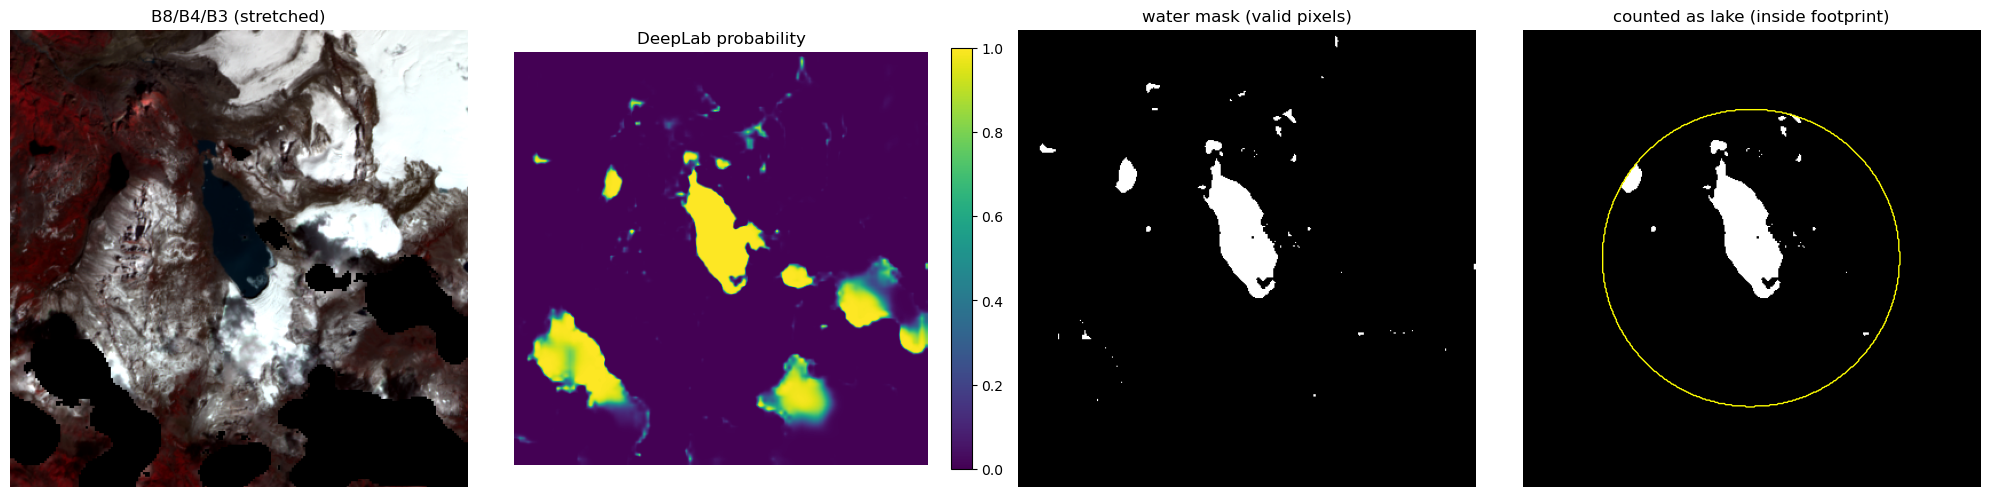

Footprint coverage: 0.9591786710913341
South Lhonak Lake (GLOF Oct 2023) | scene 20230926T043709_20230926T045046_T45RXL | 2023-09-26 | scene cloud 49%
lake area in footprint: 0.8554 km² | clear pixels in footprint: 91% | CRS EPSG:32645 | chip 400x400 px


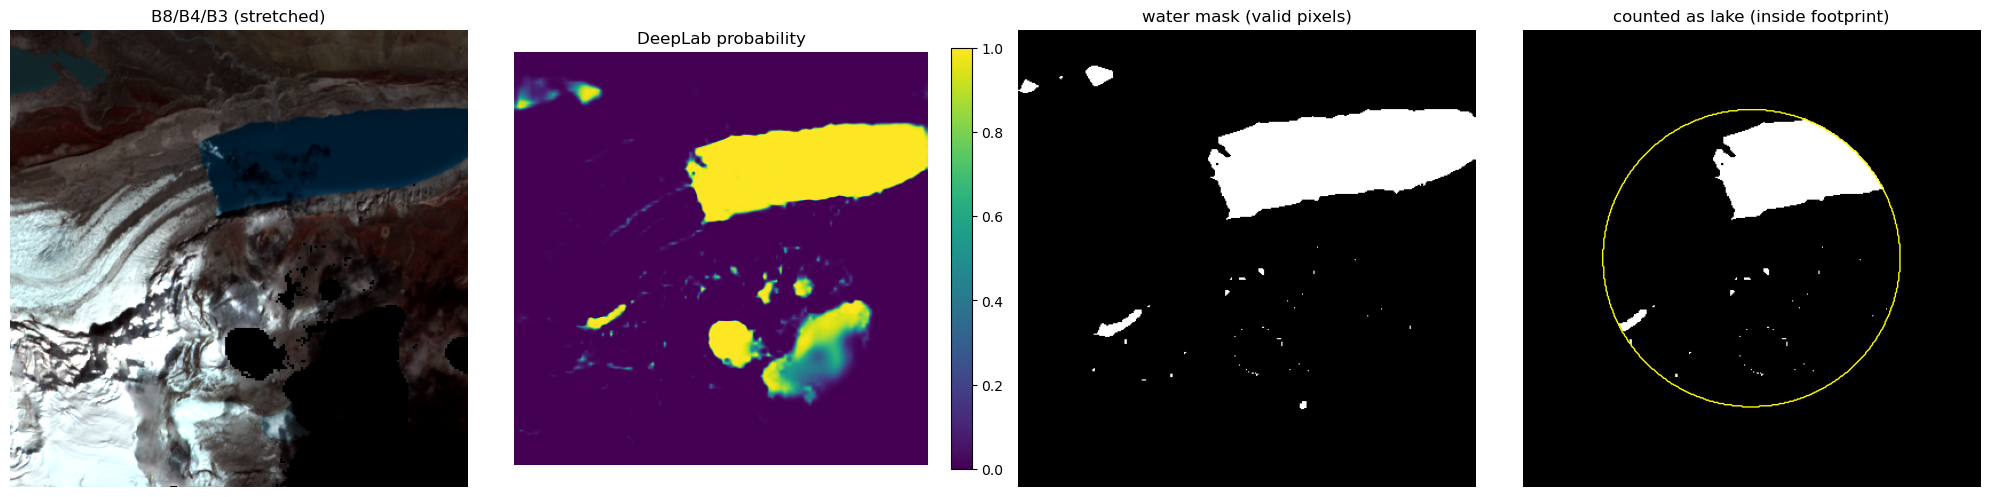

South Lhonak Lake (GLOF Oct 2023) | scene 20231024T044841_20231024T045715_T45RXL | 2023-10-24 | scene cloud 16%
lake area in footprint: 0.7662 km² | clear pixels in footprint: 100% | CRS EPSG:32645 | chip 400x400 px


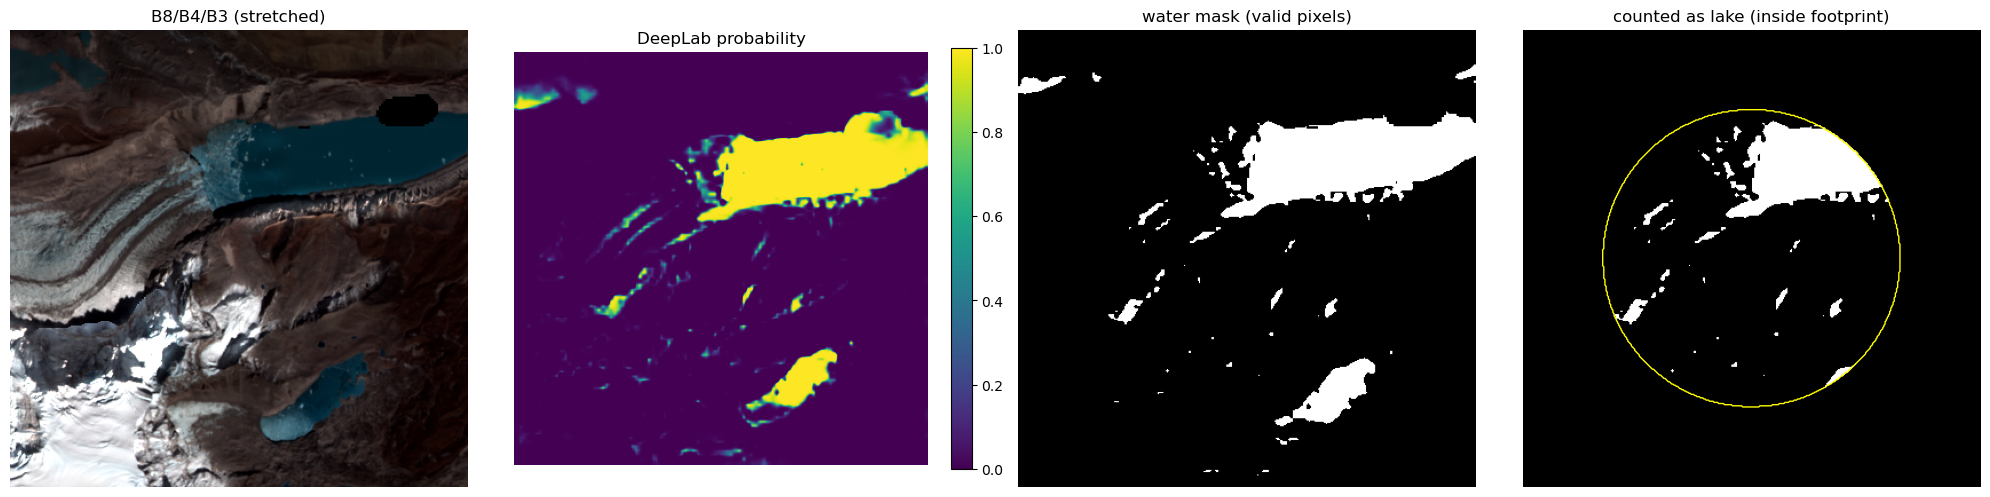

In [60]:
if RUN_LAKE_SMOKE_TEST:
    selected = lakes[min(4, len(lakes)-1)]
    measured = smoke_test(selected["lake_id"], days=120)
    print("Footprint coverage:", measured["footprint_valid_frac"])
if RUN_EVENT_IMAGES:
    smoke_test("SK_GL_01", start="2023-09-15", end="2023-10-03")
    smoke_test("SK_GL_01", start="2023-10-06", end="2023-10-25")

In [61]:
# from IPython.display import Audio
# import numpy as np

# beep = np.sin(2*np.pi*4000*np.arange(40000*2)/10000)
# Audio(beep, rate=10000, autoplay=True)

In [62]:
stats, results, snapshot = collect(cfg)
display(pd.DataFrame([{k:lake[k] for k in ["lake_id","name","level","risk","score","area_km2","data_quality"]}
                      for lake in snapshot["lakes"]]))
history_path = WORK_DIR / "training_features_history_UNVERIFIED.csv"
history = pd.read_csv(history_path)
print("Latest inference features:", cfg.features_path)
print("Dashboard snapshot:", cfg.latest_path)
print("Cumulative live rows:", len(history), "at", history.assessed_at.nunique(), "assessment times")
print("Cumulative labeling file:", history_path)

Loaded cached registry: 80 lakes  (/mnt/custom-file-systems/s3/shared/GLOF/discovered_lake_registry.csv)
Ingest: 0 lake-scenes to process this cycle (0 left in backlog)
[GLOF RED] Pyungru Tal: Optical drawdown: 0.007 km² is 95% below the 4-scene baseline (0.138 km², z=-4.4) | Near-complete drawdown (≥ 60%) | SAR water area +106% above same-orbit baseline (z=10.6, orbit 165, 2026-10-09)
[GLOF RED] Syantyankti Lake: Optical drawdown: 0.020 km² is 91% below the 7-scene baseline (0.218 km², z=-5.7) | Near-complete drawdown (≥ 60%) | SAR water area +82% above same-orbit baseline (z=8.2, orbit 165, 2026-10-09)
[GLOF ORANGE] Sikkim_East_Nepal lake b048: Optical drawdown: 0.228 km² is 75% below the 3-scene baseline (0.912 km², z=-6.0) | Near-complete drawdown (≥ 60%)
[GLOF ORANGE] Sikkim_East_Nepal lake 2c68: Optical drawdown: 0.000 km² is 100% below the 10-scene baseline (0.774 km², z=-14.4) | Near-complete drawdown (≥ 60%)


,lake_id,name,level,risk,score,area_km2,data_quality
0,UK_GL_01,Kedartal,GREEN,low,1,0.0495,RECENT_CHANGE_MEASUREMENTS
1,UK_GL_02,Vasudhara Tal,GREEN,low,0,0.3674,RECENT_CHANGE_MEASUREMENTS
2,UK_GL_03,Mabang Tal (Surya Sarovar),YELLOW,watch,3,0.2025,RECENT_CHANGE_MEASUREMENTS
3,UK_GL_04,Pyungru Tal,RED,high,6,0.0066,RECENT_CHANGE_MEASUREMENTS
4,UK_GL_05,Masar Tal (Bhilangna Lake),GREEN,low,0,0.1213,RECENT_CHANGE_MEASUREMENTS
...,...,...,...,...,...,...,...
75,HKH_0f8d5c16,Sikkim_East_Nepal lake 5c16,GREEN,low,0,0.0016,RECENT_CHANGE_MEASUREMENTS
76,HKH_2d322c68,Sikkim_East_Nepal lake 2c68,ORANGE,high,5,0.0003,RECENT_CHANGE_MEASUREMENTS
77,HKH_e4fbeb42,Sikkim_East_Nepal lake eb42,GREEN,low,0,0.8260,RECENT_CHANGE_MEASUREMENTS
78,HKH_6f54e40a,Sikkim_East_Nepal lake e40a,GREEN,low,0,0.0731,RECENT_CHANGE_MEASUREMENTS


Latest inference features: /mnt/custom-file-systems/s3/shared/GLOF/features
Dashboard snapshot: /mnt/custom-file-systems/s3/shared/GLOF/latest_path
Cumulative live rows: 94 at 2 assessment times
Cumulative labeling file: /mnt/custom-file-systems/s3/shared/GLOF/training_features_history_UNVERIFIED.csv


## 6. Build historical JEV candidate rows

This section adds actual historical assessment clocks, rather than exporting only today's snapshot. It first backfills the entire requested interval plus a warmup period into a separate stable database, then samples each selected lake. Completed rows are checkpointed after each clock; rerunning skips existing sample IDs. Existing live history is preserved.

The default historical profile uses optical and SAR only. It leaves weather, seismic and GPM fields missing unless the optional dated context CSV supplies them. It never requests current weather for a past clock. The 48-hour satellite availability lags are modeling assumptions: acquisition timestamps do not establish when a product was available operationally. Every row records `ASSUMED_SATELLITE_LAGS`. Review this assumption for your experiment; the verified training export excludes these rows unless `ALLOW_ASSUMED_SATELLITE_LAGS_FOR_TRAINING=True`. This switch documents accepting the assumption; it does not turn it into measured availability.

Optional `HIST_CONTEXT_CSV` columns: `lake_id,context_at,available_at` plus any `wx_*`, `eq_*`, and `gpm_rain_24h_mm` feature columns. Each record must represent that exact assessment clock's feature window and be available by that clock. Supply forecast rain from a dated forecast issued before the assessment, never from future realized rainfall. Duplicate lake/clock records are rejected. Missing records remain missing. File content is fingerprinted to prevent silently changing an existing dataset profile.

For forecast archives, see [Open-Meteo Single Runs](https://open-meteo.com/en/docs/single-runs-api): a run is selected by initialization time. Its ECMWF IFS archive starts in March 2024, so this source does not cover the supplied 2023 event window. [Historical Weather](https://open-meteo.com/en/docs/historical-weather-api) contains reanalysis; it is not automatically an as-issued forecast or a verified real-time observation stream. [NASA IMERG](https://gpm.nasa.gov/data/imerg) distinguishes low-latency runs from the delayed Final product, which is why the original Earth Engine Final IMERG field is disabled by default here.

In [63]:
def load_historical_context(path):
    if path is None:
        return {}
    frame = pd.read_csv(path)
    required = {"lake_id", "context_at", "available_at"}
    if not required.issubset(frame.columns):
        raise ValueError("Historical context needs lake_id, context_at, available_at")
    frame["context_at"] = pd.to_datetime(frame.context_at, utc=True, errors="raise")
    frame["available_at"] = pd.to_datetime(frame.available_at, utc=True, errors="raise")
    if frame[["context_at", "available_at"]].isna().any().any():
        raise ValueError("Historical context timestamps cannot be missing")
    if (frame.available_at > frame.context_at).any():
        raise ValueError("Historical context contains information unavailable at its assessment clock")
    if frame.duplicated(["lake_id", "context_at"]).any():
        raise ValueError("Duplicate historical context lake/clock")
    allowed = [name for name in FEATURE_COLUMNS if name.startswith(("wx_", "eq_")) or name == "gpm_rain_24h_mm"]
    return {(str(row["lake_id"]), utc(row["context_at"]).isoformat()):
            {name:clean(row.get(name)) for name in allowed} for row in frame.to_dict("records")}

def historical_clock_rows(lakes, clock, context):
    clock = utc(clock)
    optical_cutoff = clock - pd.Timedelta(hours=S2_AVAILABILITY_LAG_HOURS)
    sar_cutoff = clock - pd.Timedelta(hours=S1_AVAILABILITY_LAG_HOURS)
    def sar_job(lake):
        try:
            result = sar_check(lake, sar_cutoff)
            if result.get("available") and (clock-utc(result["s1_time"])).total_seconds()/86400 > 12:
                return {"available":False, "reason":"SAR too old at the assessment clock"}
            return result
        except Exception as error:
            return {"available":False, "error":repr(error)}
    with ThreadPoolExecutor(EE_WORKERS) as pool:
        sars = list(pool.map(sar_job, lakes))
    rows = []
    for lake, sar in zip(lakes, sars):
        obs = latest_reliable_obs(lake["lake_id"], optical_cutoff)
        if obs and (clock-utc(obs["scene_time"])).total_seconds()/86400 > D.RECENT_OPTICAL_DAYS:
            obs = None
        hist = reliable_history(lake["lake_id"], obs["scene_time"]) if obs else pd.DataFrame()
        result = assess(obs, hist, sar, {}, clock)
        result["metrics"].update(context.get((str(lake["lake_id"]), clock.isoformat()), {}))
        row = monitor_to_training_rows([(lake, result)], clock)[0]
        row.update(sample_id=f"HIST__{lake['lake_id']}__{clock.strftime('%Y%m%dT%H%M%SZ')}",
                   sampling_mode="historical", feature_availability_policy="ASSUMED_SATELLITE_LAGS",
                   optical_time=result["metrics"].get("optical_time"),
                   sar_time=result["metrics"].get("sar_time"),
                   s2_availability_lag_hours=S2_AVAILABILITY_LAG_HOURS,
                   s1_availability_lag_hours=S1_AVAILABILITY_LAG_HOURS,
                   input_usable=not measurement_gate(row, clock))
        rows.append(row)
    return rows

def build_historical_candidates(cfg):
    global BACKFILL_DAYS, SAVE_QUICKLOOKS
    start, end = utc(HIST_START), utc(HIST_END)
    if end < start or end > utc(datetime.now(timezone.utc)):
        raise ValueError("Historical dates must be ordered and in the past")
    if HIST_STEP_HOURS <= 0 or MAX_HISTORICAL_CLOCKS_PER_RUN <= 0 or HIST_WARMUP_DAYS < D.BASELINE_DAYS:
        raise ValueError("Positive sampling controls and warmup >= baseline_days are required")
    if S2_AVAILABILITY_LAG_HOURS < 0 or S1_AVAILABILITY_LAG_HOURS < 0:
        raise ValueError("Availability lag cannot be negative")
    clocks = pd.date_range(start, end, freq=pd.Timedelta(hours=HIST_STEP_HOURS))
    work = Path(HIST_WORK_DIR)
    work.mkdir(parents=True, exist_ok=True)
    hist_cfg = MapDict(cfg.copy())
    hist_cfg.update(work_path=work, db_path=work/"historical_monitor.sqlite", adopt_unversioned_db=False)
    # Freeze the selected registry; historical configure cannot trigger fresh discovery.
    frozen = Path(cfg.work_path)/"lake_registry.csv"
    hist_cfg.update(registry_mode="csv", registry_path=frozen)
    # Include padding for a stale latest optical scene and assumed product latency.
    padding = D.RECENT_OPTICAL_DAYS + int(np.ceil(max(S2_AVAILABILITY_LAG_HOURS, S1_AVAILABILITY_LAG_HOURS)/24))
    hist_cfg["backfill_days"] = int(np.ceil((end-start).total_seconds()/86400)) + HIST_WARMUP_DAYS + padding + 1
    path = work/"historical_training_UNVERIFIED.csv"
    old_quicklooks = SAVE_QUICKLOOKS
    try:
        SAVE_QUICKLOOKS = False
        lakes = configure(hist_cfg)
        profile = {"s2_lag_hours":S2_AVAILABILITY_LAG_HOURS, "s1_lag_hours":S1_AVAILABILITY_LAG_HOURS,
                   "context_sha256":sha256_file(HIST_CONTEXT_CSV) if HIST_CONTEXT_CSV else None,
                   "measurement_signature":json.loads(DB_PATH.with_name(DB_PATH.name+".measurement_signature.json").read_text())}
        profile_path = work/"dataset_profile.json"
        if profile_path.exists() and json.loads(profile_path.read_text()) != profile:
            raise ValueError("Historical feature profile changed. Use a new historical work directory")
        atomic_json(profile_path, profile)
        stats = None
        for pass_number in range(MAX_BACKFILL_PASSES):
            stats = ingest_cycle(lakes, end)
            print("Historical backfill", pass_number+1, stats)
            if stats["backlog"] == 0 and stats.get("listing_failed",0) == 0:
                break
        if stats["backlog"] or stats.get("listing_failed",0):
            print("Historical imagery incomplete; rerun this cell before assessment sampling.")
            return {"status":"BACKFILL_PENDING", "path":str(path), "stats":stats}
        context = load_historical_context(HIST_CONTEXT_CSV)
        existing = pd.read_csv(path) if path.exists() else pd.DataFrame()
        done = set(existing.sample_id) if not existing.empty else set()
        processed = 0
        for clock in clocks:
            pending_lakes = [lake for lake in lakes if f"HIST__{lake['lake_id']}__{clock.strftime('%Y%m%dT%H%M%SZ')}" not in done]
            if not pending_lakes:
                continue
            if processed >= MAX_HISTORICAL_CLOCKS_PER_RUN:
                break
            rows = historical_clock_rows(pending_lakes, clock, context)
            accumulate_rows(rows, path)
            done.update(row["sample_id"] for row in rows)
            processed += 1
            print(f"Checkpoint {clock.isoformat()}: saved {len(rows)} candidate rows")
        total = len(lakes)*len(clocks)
        finished = sum(f"HIST__{lake['lake_id']}__{clock.strftime('%Y%m%dT%H%M%SZ')}" in done for clock in clocks for lake in lakes)
        status = "COMPLETE" if finished == total else "SAMPLING_PENDING"
        print(f"Historical candidates: {finished}/{total}; {status}; {path}")
        return {"status":status, "path":str(path), "completed":finished, "planned":total}
    finally:
        SAVE_QUICKLOOKS = old_quicklooks
        configure(cfg)                       # restore live DB and globals even after an error

In [65]:
cfg["download_budget"] = 1000

EE_WORKERS, DL_WORKERS, CHUNK = 100, 100, 200

if RUN_HISTORICAL_COLLECTION:
    historical_status = build_historical_candidates(cfg)
    print(historical_status)
else:
    print("Set RUN_HISTORICAL_COLLECTION=True in configuration to generate historical rows")

Ingest: 1000 lake-scenes to process this cycle (3414 left in backlog)
  processed 200/1000
  processed 400/1000
  processed 600/1000
  processed 800/1000
  processed 1000/1000
Historical backfill 1 {'processed': 1000, 'reliable': 806, 'backlog': 3414, 'failed': 0, 'listing_failed': 0}
Ingest: 1000 lake-scenes to process this cycle (2414 left in backlog)
  processed 200/1000
  processed 400/1000
  processed 600/1000
  processed 800/1000
  processed 1000/1000
Historical backfill 2 {'processed': 1000, 'reliable': 694, 'backlog': 2414, 'failed': 0, 'listing_failed': 0}
Ingest: 1000 lake-scenes to process this cycle (1414 left in backlog)
  processed 200/1000
  processed 400/1000
  processed 600/1000
  processed 800/1000
  processed 1000/1000
Historical backfill 3 {'processed': 1000, 'reliable': 456, 'backlog': 1414, 'failed': 0, 'listing_failed': 0}
Ingest: 1000 lake-scenes to process this cycle (414 left in backlog)
  processed 200/1000
  processed 400/1000
  processed 600/1000
  processe

In [67]:
import gc
gc.collect()

0

## 7. Label independently and export the JEV training CSV

The template creation cell preserves existing review files. No event time, outcome, or ground truth is invented. Fill `jev_events_REVIEW.csv` with independently verified first-onset UTC timestamps and sources. All samples within 72 hours before one event share its `episode_id`. An onset exactly 24 hours ahead belongs to class 1; an onset over 24 and up to 72 hours ahead belongs to class 2.

Fill `jev_controls_REVIEW.csv` with verified no-onset observation windows and sources. A negative is labeled only when the entire assessment→assessment+72-hour horizon is inside that window. Coverage endpoints must have elapsed. Use distinct independent control episodes, and keep overlapping windows for the same lake out of the review table. A control window conflicting with a verified event is rejected. `GREEN`, anomaly thresholds, a blank event field, and a lake's name are never used as labels.

Training output: `training_labels_VERIFIED.csv`. It retains only verified outcomes with usable lake-change inputs and an accepted feature availability policy. It reports label counts and independent episodes. The provided Qwen training notebook uses `USE_SYNTHETIC_SAMPLE=False` and `DATA_CSV` pointing to this file. Its default group split requires >=20 lake groups plus all three classes in each split. If you use a chronological split, retain whole episodes and purge at least the 72-hour forecast horizon at split boundaries. Extra nearby clocks do not add independent event episodes.

In [69]:
def create_label_templates():
    templates = {
        EVENT_LABELS_CSV:["lake_id","episode_id","event_start_utc","label_source","label_status"],
        CONTROL_LABELS_CSV:["lake_id","episode_id","coverage_start_utc","coverage_end_utc","label_source","label_status"],
    }
    for path, columns in templates.items():
        if not Path(path).exists():
            write_csv_atomic(pd.DataFrame(columns=columns), path)
        print("Review template:", path)

def read_verified_labels(path, required, time_columns):
    table = pd.read_csv(path)
    if not set(required).issubset(table.columns):
        raise ValueError(f"Missing columns in {path}: {set(required)-set(table.columns)}")
    table = table.loc[table.label_status.eq("VERIFIED")].copy()
    if table.empty:
        return table
    for key in ["lake_id","episode_id","label_source"]:
        if table[key].isna().any() or table[key].astype(str).str.strip().eq("").any():
            raise ValueError(f"Verified {key} must be nonempty in {path}")
    for key in time_columns:
        table[key] = pd.to_datetime(table[key], utc=True, errors="raise")
        if table[key].isna().any() or (table[key] > utc(datetime.now(timezone.utc))).any():
            raise ValueError(f"Verified {key} must be nonmissing and in the past")
    return table

def label_candidates(frame, events, controls):
    out = frame.copy()
    for key in ["episode_id", "event_start_utc", "label_verified_until_utc", "event_class", "label_source", "label_status"]:
        out[key] = out[key].astype(object) if key in out else None
    for i, row in out.iterrows():
        if row.get("label_status") == "VERIFIED":
            continue
        at = utc(row.assessed_at)
        future = events.loc[(events.lake_id==row.lake_id) & (events.event_start_utc>at) &
                            (events.event_start_utc<=at+pd.Timedelta(hours=72))] if not events.empty else events
        windows = controls.loc[(controls.lake_id==row.lake_id) & (controls.coverage_start_utc<=at) &
                               (controls.coverage_end_utc>=at+pd.Timedelta(hours=72))] if not controls.empty else controls
        if not future.empty and not windows.empty:
            raise ValueError(f"Event/control conflict for {row.sample_id}")
        if len(windows)>1:
            raise ValueError(f"Overlapping control episodes for {row.sample_id}")
        if not future.empty:
            event = future.sort_values("event_start_utc").iloc[0]
            hours = (event.event_start_utc-at).total_seconds()/3600
            updates = {"episode_id":event.episode_id,"event_start_utc":event.event_start_utc.isoformat(),
                       "label_verified_until_utc":event.event_start_utc.isoformat(),
                       "event_class":1 if hours<=24 else 2,"label_source":event.label_source,"label_status":"VERIFIED"}
        elif not windows.empty:
            window = windows.iloc[0]
            updates = {"episode_id":window.episode_id,"event_start_utc":None,
                       "label_verified_until_utc":window.coverage_end_utc.isoformat(),
                       "event_class":0,"label_source":window.label_source,"label_status":"VERIFIED"}
        else:
            continue
        for key, value in updates.items():
            out.at[i,key] = value
    return out

def export_verified_training():
    events = read_verified_labels(EVENT_LABELS_CSV,
        ["lake_id","episode_id","event_start_utc","label_source","label_status"], ["event_start_utc"])
    controls = read_verified_labels(CONTROL_LABELS_CSV,
        ["lake_id","episode_id","coverage_start_utc","coverage_end_utc","label_source","label_status"],
        ["coverage_start_utc","coverage_end_utc"])
    if not controls.empty and (controls.coverage_end_utc<=controls.coverage_start_utc).any():
        raise ValueError("Control window endpoints must be ordered")
    paths = [WORK_DIR/"training_features_history_UNVERIFIED.csv", Path(HIST_WORK_DIR)/"historical_training_UNVERIFIED.csv"]
    all_rows = []
    for path in paths:
        if path.exists():
            reviewed = label_candidates(pd.read_csv(path), events, controls)
            write_csv_atomic(reviewed, path)
            all_rows.append(reviewed)
    if not all_rows:
        print("No candidate data collected yet")
        return pd.DataFrame()
    data = pd.concat(all_rows, ignore_index=True).drop_duplicates("sample_id", keep="first")
    verified = data.label_status.eq("VERIFIED")
    usable = pd.Series([not measurement_gate(row, row["assessed_at"])
                        for row in data.to_dict("records")], index=data.index)
    accepted = data.feature_availability_policy.eq("RECORDED_LIVE")
    if ALLOW_ASSUMED_SATELLITE_LAGS_FOR_TRAINING:
        accepted |= data.feature_availability_policy.eq("ASSUMED_SATELLITE_LAGS")
    selected = data.loc[verified & usable & accepted].copy()
    for key in ["episode_id", "lake_id", "label_source"]:
        if selected[key].isna().any() or selected[key].astype(str).str.strip().eq("").any():
            raise ValueError(f"Exported verified rows need nonempty {key}")
    selected["event_class"] = [derive_target(row) for row in selected.to_dict("records")]
    print("Candidates:",len(data), "Verified labels:",int(verified.sum()), "Exportable:",len(selected))
    print("Feature-missing rows:",int((~usable).sum()), "Availability-policy exclusions:",int((~accepted).sum()))
    if selected.empty:
        print("No new training CSV written. Existing exports, if any, are unchanged.")
        return selected
    if selected.is_synthetic.map(bool_value).eq(True).any():
        raise ValueError("Synthetic records are excluded from this real-data export")
    target = WORK_DIR/"training_labels_VERIFIED.csv"
    write_csv_atomic(selected, target)
    print("Training CSV:",target)
    print("Class counts:",selected.event_class.value_counts().sort_index().to_dict())
    print("Lakes:",selected.lake_id.nunique(), "Independent episodes:",selected.episode_id.nunique())
    if set(selected.event_class) != {0,1,2}:
        print("Collect verified examples of all three classes before running the supplied training notebook.")
    if selected.lake_id.nunique()<20:
        print("Default four-way lake-group split needs at least 20 lakes; review your split design.")
    return selected

create_label_templates()
if RUN_LABEL_EXPORT:
    verified_training = export_verified_training()
else:
    print("Fill review templates, then enable RUN_LABEL_EXPORT to export verified training rows")

Review template: /mnt/custom-file-systems/s3/shared/GLOF/jev_events_REVIEW.csv
Review template: /mnt/custom-file-systems/s3/shared/GLOF/jev_controls_REVIEW.csv
Fill review templates, then enable RUN_LABEL_EXPORT to export verified training rows


## 8. Collection parameters and dataset size

Start with the supplied 14 seeds and the 2023 interval to test the complete workflow. For a broader pilot, use a reviewed 30–50-lake registry, 6–12 months of sampling, `HIST_STEP_HOURS=24`, and `HIST_WARMUP_DAYS=120`. Around independently documented outburst episodes, use a separate date window with `HIST_STEP_HOURS=6`; retain one episode ID for its correlated pre-event samples. These are engineering starting points, not validated accuracy guarantees.

| Control | CPU pilot | Larger collection | Effect |
|---|---:|---:|---|
| Registry size | 14 existing seeds | 30–50 reviewed lakes | Number of lakes per assessment clock |
| `DOWNLOAD_BUDGET_CONFIG` | 24 | 48–96 after a throughput check | Images processed per pass |
| `MAX_BACKFILL_PASSES` | 4 | 10–20 if longer jobs are acceptable | Work per cell execution |
| `HIST_STEP_HOURS` | 24 | 24 generally, 6 around events | Assessment clocks per day |
| `HIST_WARMUP_DAYS` | 120 | 120–180 with matching baseline settings | Imagery before the sampled interval |
| `MAX_HISTORICAL_CLOCKS_PER_RUN` | 4 | 10–20 after a pilot | Checkpoints produced per execution |
| Footprint validity | 0.80 | 0.80 | Cloud-free quality gate; retain it |
| `EE_WORKERS`, `DL_WORKERS` | 2, 2 | Start at 2, 2 | Request concurrency; increase cautiously |

Approximate candidate count = lakes × assessment clocks. For exactly 365 daily clocks, 50 lakes yield 18,250 candidates; 100 lakes yield 36,500. At six-hour intervals the count is roughly four times larger. Missing observations, feature quality checks, outcome verification and accepted availability policies reduce the usable training count. More rows do not replace more independent lake/event episodes or a valid held-out test.

`MAX_LAKES=50` only changes row count when your CSV/discovery registry actually contains that many lakes. It does not create lakes in seed mode. `download_budget`, region extent, augmentation, and a longer optical baseline do not themselves produce labels.

Recommended sequence: pilot a few lakes/dates → inspect area/quality outputs → expand the reviewed registry → finish historical backfill → repeat checkpointed historical sampling → curate event and control evidence → export verified rows → use the Qwen/Jev training notebook. Keep all rows from the same event episode in one split. Evaluate on representative prevalence; oversampling training positives should not alter the held-out evaluation set.

Historical data sources: [Earth Engine data catalog](https://developers.google.com/earth-engine/datasets/), [Open-Meteo Single Runs](https://open-meteo.com/en/docs/single-runs-api), [Open-Meteo historical weather](https://open-meteo.com/en/docs/historical-weather-api), [NASA IMERG](https://gpm.nasa.gov/data/imerg). Request caching and bounded concurrency follow [Earth Engine usage guidance](https://developers.google.com/earth-engine/guides/usage).

Validation performed for this delivered notebook: Python cell compilation; persistent database reuse and model-change guard; cumulative export and label preservation; historical cutoff, resume and partial-backfill behavior using mocked remote calls; label horizon boundaries and event/control conflicts. Actual TensorFlow model inference, Earth Engine requests, AWS execution, and training require your model and credentials and were not run in this environment.

In [ ]:
clocks = pd.date_range(utc(HIST_START), utc(HIST_END), freq=pd.Timedelta(hours=HIST_STEP_HOURS))
print("Configured historical clocks:",len(clocks))
print("Planned candidate rows with current registry:",len(lakes)*len(clocks))
for path in [WORK_DIR/"training_features_history_UNVERIFIED.csv", Path(HIST_WORK_DIR)/"historical_training_UNVERIFIED.csv"]:
    if path.exists():
        frame = pd.read_csv(path)
        print(path.name, {"rows":len(frame),"lakes":frame.lake_id.nunique(),
              "clocks":frame.assessed_at.nunique(),"verified":int(frame.label_status.eq("VERIFIED").sum())})